In [1]:
import matplotlib_inline
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.image as mpimg
import pickle
import matplotlib.ticker as ticker

from joblib import Parallel, delayed
import multiprocessing
from scipy.stats import gaussian_kde,rv_continuous
from scipy import stats
from scipy.interpolate import interp1d

from astropy.coordinates import SkyCoord
import astropy.units as u

In [2]:
# Some Constats and Units
pc = 3.086E+18       # 1 pc, cm 
mh = 1.6735575e-24   # Hydrogen mass, g 
me = 9.1093837e-28   # Electron mass, g 
eV = 1.602176634e-12 # ElectronVolt, erg
Jy = 1.0E-23         # 1 Jansky (erg/s/cm2/Hz), cgs
kb = 1.380649e-16   # K boltzman, cgs
h =  6.6261e-27    # Plank constant, cgs 
c = 3.0e10           # Speed of light, cgs 
Na = 6.022e+23       # Avogadro's number
Z = 1                  # Hydrogen atomic number
e = 4.8e-10          # Electric charge cm3/2 g1/2 s-1

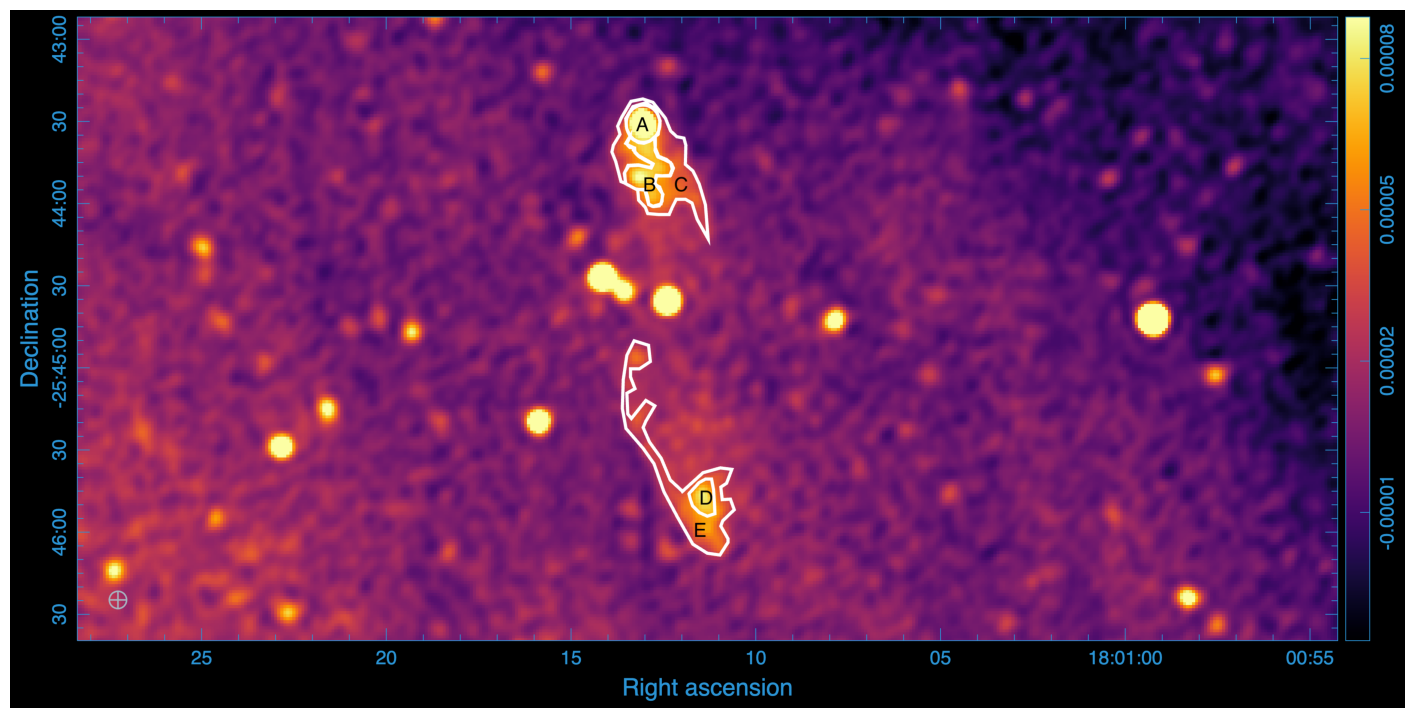

In [3]:
img_model = mpimg.imread('Try2_modeljet.png')
plt.figure(figsize=(18,18))
plt.imshow(img_model)
plt.axis('off')
plt.show()

In [4]:
# Some useful functions

# Gaunt factor 
def gaunt(nu, T, z, gammalor=0.5772156649):
    # The Gaunt factor
    F1 = 128.*(1**2)*(kb**3)*(T**3)    
    F2 = me * (e**4)*(nu**2)*(z**2)
    
    G = (3**0.5 / (2.*np.pi)) * (np.log(F1/F2) - gammalor**(1/2))
    
    return G

# Electron density (unit volume)
def neuv(F, dist, bmaj, DR, T, nu, Z):
    L = F*Jy*4*np.pi*(dist*1e3*pc)**2 #  Average monochormatic ring luminosity in erg/sec/Hz
    Vol = ((np.pi)*(bmaj/2)*(bmaj/2))*(DR)*(0.048*d10*pc)**3
    kappa_nu = L / Vol
    C_radio = 6.8*1e-38
    ne_squared = kappa_nu/(C_radio*(T**(-0.5)) * gaunt(nu, T, Z)*np.exp((h*nu)/(kb*T)))
    n_e_uv = (ne_squared**0.5) # units: cm^-3
    return n_e_uv

# Electron density (cone)
def necone(F, dist, d, height, T, nu, Z):
    L = F*Jy*4*np.pi*(dist*1e3*pc)**2 # Monochormatic luminosity in erg/sec/Hz
    Vol = (1/3)*np.pi*((d/2)**2)*height  # Cone volume
    kappa_nu = L / Vol
    C_radio = 6.8*1e-38
    ne_squared = kappa_nu/(C_radio*(T**(-0.5)) * gaunt(nu, T, Z)*np.exp((h*nu)/(kb*T)))
    ne = (ne_squared**0.5) # units: cm^-3
    return ne

def MonoLum(F, eF, dist):
    L = F*Jy*4*np.pi*(dist*1e3*pc)**2
    eL = eF*Jy*4*np.pi*(dist*1e3*pc)**2
    return L, eL

## Thermal (bremmstrahlung) emission (C, D and E regions)

### Electron density $n_e$ estimate

$$ n_e = \sqrt{\dfrac{\epsilon_{\nu}}{g(\nu,T)\sqrt{T}C_{radio}exp\left(\dfrac{h\nu}{k_bT}\right)}}$$

where:

$$ \epsilon_{\nu} = \dfrac{L_{\nu}}{V}$$

and

$$ C_{radio} = 6.8x10^{-38} erg s^{-1} cm^{-3} Hz^{-1}$$

In [5]:
# Observation quantities
nu = 1.284e9   # Hz
bmaj = 6.33185  # arcsec
bmin = bmaj

# Source quantities
d10 = 0.85    # distance in units of 10 kpc
incl = 61     # inclination to the los, deg
eincl = 2   
# C, D and E region are the ones that are compatible with flat spectrum and so with thermal emission
# D region (as a cone)
FD = 0.0001377817              # emission of the D region in Jy (integrated flux density)
eFD = FD*0.1
LumD, eLumD = MonoLum(FD, eFD, d10*10)
FDmean = 0.0000685122              # emission of the D region in Jy (averaged flux density)
eFDmean = FDmean*0.1
hasec = 12.28302               # height of the cone region in arcsec
hcm = hasec*0.048*d10*pc/np.sin(incl*np.pi/180)   # height of the cone region in cm (also corrected for inclination angle)
hcmin = hasec*0.048*d10*pc/np.sin((incl+eincl)*np.pi/180)
hcmax = hasec*0.048*d10*pc/np.sin((incl-eincl)*np.pi/180)
#hcm = hasec*0.048*d10*pc   # height of the cone region in cm 
dasec = 9.542686               # diameter of the cone region in arcsec
dcm = dasec*0.048*d10*pc       # diameter of the cone region in cm
DRD = np.mean([2, 9.6])         # D ring thickness (average) in arcsec --> to be reviewed
DRDstd = np.std([2, 9.6])
DRDcm = (DRD)*(0.048*d10*pc)
DRDstdcm = (DRDstd)*(0.048*d10*pc)
# E region (averaged values)
FEmean = 0.00003744104  
eFEmean = FEmean*0.1
LumE, eLumE = MonoLum(FEmean, eFEmean, d10*10)
DRE = np.mean([2, 25])         # E ring thickness (average) in arcsec --> to be reviewed
DREstd = np.std([2, 25])
DREcm = (DRE)*(0.048*d10*pc)
DREstdcm = (DREstd)*(0.048*d10*pc)
# C region (averaged values)
FCmean =  0.00004155253425
eFCmean = FCmean*0.1
DRC = np.mean([7.35, 25])         # C ring thickness (average) in arcsec --> to be reviewed
DRCstd = np.std([7.35, 25])
DRCcm = (DRC)*(0.048*d10*pc)
DRCstdcm = (DRCstd)*(0.048*d10*pc)
LumC, eLumC = MonoLum(FCmean, eFCmean, d10*10)

#gammalor = 1.02                # Lorentz factor of the jet (for some reason I remember this is a good choise for a lower limit) v = 0.2c
gammalor = 1.002

# Assumptions (cone region D is emitting thermal radiation)
Tmax = 3e6
Tmin = 1e4

gau = gaunt(nu, Tmin, Z)
nemaxD = necone(FD, d10*10, dcm, hcm, Tmax, nu, Z)
neminD = necone(FD, d10*10, dcm, hcm, Tmin, nu, Z)
print('Min number density in D region [1/cm3]:', neminD)
print('Max number density in D region [1/cm3]:', nemaxD)
print('\n')
nemaxDuv = neuv(FD, d10*10, bmaj, DRD, Tmax, nu, Z)
neminDuv = neuv(FD, d10*10, bmaj, DRD, Tmin, nu, Z)
print('Min number density in D region (unit volume) [1/cm3]:', neminDuv)
print('Max number density in D region (unit volume) [1/cm3]:', nemaxDuv)
print('\n')
nemaxE = neuv(FEmean, d10*10, bmaj, DRE, Tmax, nu, Z)
neminE = neuv(FEmean, d10*10, bmaj, DRE, Tmin, nu, Z)
print('Min number density in E region (unit volume) [1/cm3]:', neminE)
print('Max number density in E region (unit volume) [1/cm3]:', nemaxE)
print('\n')
nemaxC = neuv(FCmean, d10*10, bmaj, DRC, Tmax, nu, Z)
neminC = neuv(FCmean, d10*10, bmaj, DRC, Tmin, nu, Z)
print('Min number density in C region (unit volume) [1/cm3]:', neminC)
print('Max number density in C region (unit volume) [1/cm3]:', nemaxC)

vmin = np.sqrt((16*kb*Tmin)/(3*mh))
vmax = np.sqrt((16*kb*Tmax)/(3*mh))  # Both in cm/s
print('\n')
print('Max velocity [cm/s]', vmax)
print('Min velocity [cm/s]', vmin)
print('\n')
print('D region monochromatic luminosity [erg/s/Hz]:', LumD,'+/-', eLumD)
print('E region average monochromatic luminosity [erg/s/Hz]:', LumE,'+/-', eLumE)
print('C region average monochromatic luminosity [erg/s/Hz]:', LumC,'+/-', eLumC)

Min number density in D region [1/cm3]: 57.956074113762384
Max number density in D region [1/cm3]: 190.42654478214885


Min number density in D region (unit volume) [1/cm3]: 78.47065917610136
Max number density in D region (unit volume) [1/cm3]: 257.8314132242824


Min number density in E region (unit volume) [1/cm3]: 26.8122089794782
Max number density in E region (unit volume) [1/cm3]: 88.09700090997907


Min number density in C region (unit volume) [1/cm3]: 25.80489768995957
Max number density in C region (unit volume) [1/cm3]: 84.78727347732791


Max velocity [cm/s] 36331331.41040845
Min velocity [cm/s] 2097590.3969816826


D region monochromatic luminosity [erg/s/Hz]: 1.1913273104556356e+19 +/- 1.1913273104556357e+18
E region average monochromatic luminosity [erg/s/Hz]: 3.237333657797941e+18 +/- 3.237333657797942e+17
C region average monochromatic luminosity [erg/s/Hz]: 3.5928333639857956e+18 +/- 3.592833363985796e+17


In [6]:
((np.pi)*(bmaj/2)*(bmaj/2))*(DRC)*(0.048*d10*pc)**3

1.0166317319091128e+54

In [7]:
1.2*60*DRC**2*(0.048*d10*pc)**3/np.sin(incl*np.pi/180)

4.2990259914031267e+55

In [8]:
(bmaj/2)*(0.048*d10)

0.12916974

In [9]:
DRE

13.5

In [10]:
25*(0.048*d10)

1.02

### MC-based estimate of $n_e$ (bremhstralhung regions)

In [11]:
niter = 5000
ncores = 1
perc_low = 16
perc_up = 84

#perc_low = 0.1
#perc_up = 99.9

Tmean = np.mean([Tmin,Tmax])
Tstd = np.std([Tmin,Tmax])
np.random.seed(105)
#FDrand = np.random.normal(FD, eFD, niter)
#FDrand_mean = np.random.normal(FDmean, eFDmean, niter)
FDrand = np.random.uniform(FD-eFD, eFD+eFD, niter)
FDrand_mean = np.random.uniform(FDmean-eFDmean, FDmean+eFDmean, niter)
#hcmrand = np.random.normal(np.mean([hcmin, hcmax]), np.std([hcmin, hcmax]), niter)
hcmrand = np.random.uniform(hcmin, hcmax, niter)
#FErand = np.random.normal(FEmean, eFEmean, niter)
#FCrand = np.random.normal(FCmean, eFCmean, niter)
FErand = np.random.uniform(FEmean-eFEmean, FEmean+eFEmean, niter)
FCrand = np.random.uniform(FCmean-eFCmean, FCmean+eFCmean, niter)
#Trand = np.random.normal(Tmean, Tstd, niter)
Trand = np.random.uniform(Tmin,Tmax, niter)
#DRDrand = np.random.normal(DRD, DRDstd, niter)
#DRErand = np.random.normal(DRE, DREstd, niter)
#DRCrand = np.random.normal(DRC, DRCstd, niter)
DRDrand = np.random.uniform(DRD-DRDstd, DRD+DRDstd, niter)
DRErand = np.random.uniform(DRE-DREstd, DRE+DREstd, niter)
DRCrand = np.random.uniform(DRC-DRCstd, DRC+DRCstd, niter)

In [12]:
(1/3)*np.pi*((dcm/2)**2)*np.median(hcmrand)  # Cone volume

6.688500528145633e+53

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


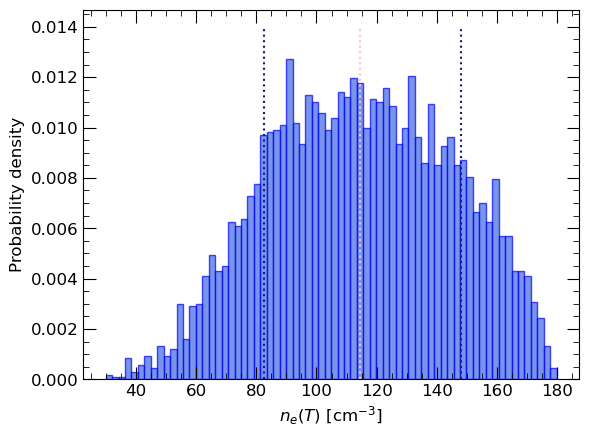

Median = 114.39630900627074 ; Lower limit =  82.62783964073128 ; Upper limit =  148.05413990506966


In [13]:
neD = Parallel(n_jobs=ncores, verbose=5)(delayed(necone)(FDrand[i], d10*10, dcm, hcmrand[i], Trand[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neD,50)
low_lim = np.nanpercentile(neD,perc_low)
high_lim = np.nanpercentile(neD,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neD,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
neDmed = median
neDlow = low_lim
neDup = high_lim

In [14]:
neDlow0 = neDlow/4
neDup0 = neDup/4
print(neDlow0, neDup0)

20.65695991018282 37.013534976267415


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


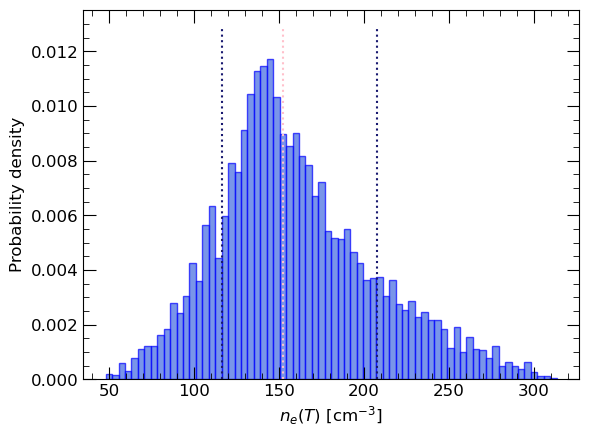

Median = 152.2564604142127 ; Lower limit =  116.54452373402569 ; Upper limit =  207.2875022519655


In [15]:
neDD = Parallel(n_jobs=ncores, verbose=5)(delayed(neuv)(FDrand_mean[i], d10*10, bmaj, DRDrand[i], Trand[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neDD,50)
low_lim = np.nanpercentile(neDD,perc_low)
high_lim = np.nanpercentile(neDD,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neDD,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
#neDmed = median
#neDlow = low_lim
#neDup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


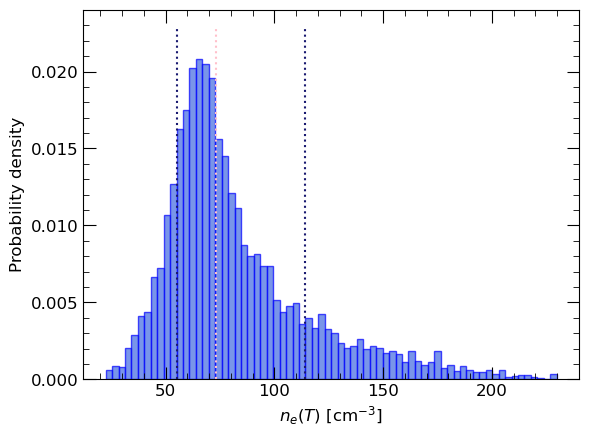

Median = 72.98204789191814 ; Lower limit =  55.32754480042887 ; Upper limit =  114.33190711230797


In [16]:
neE = Parallel(n_jobs=ncores, verbose=5)(delayed(neuv)(FErand[i], d10*10, bmaj, DRErand[i], Trand[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neE,50)
low_lim = np.nanpercentile(neE,perc_low)
high_lim = np.nanpercentile(neE,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neE,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
neEmed = median
neElow = low_lim
neEup = high_lim

In [17]:
neElow0 = neElow/4
neEup0 = neEup/4
print(neElow0, neEup0)

13.831886200107217 28.582976778076993


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


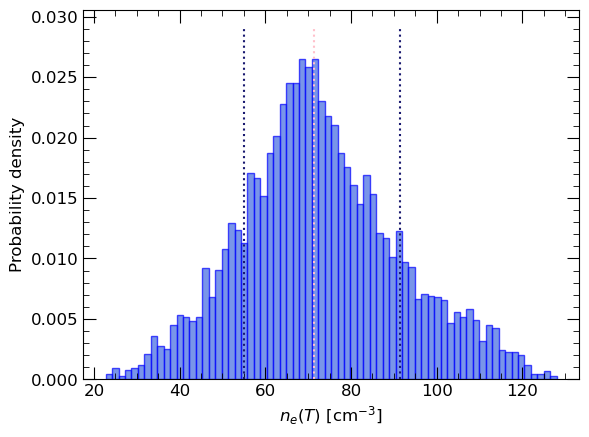

Median = 71.36806117025665 ; Lower limit =  54.9825879278265 ; Upper limit =  91.4153490519025


In [18]:
neC = Parallel(n_jobs=ncores, verbose=5)(delayed(neuv)(FCrand[i], d10*10, bmaj, DRCrand[i], Trand[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neC,50)
low_lim = np.nanpercentile(neC,perc_low)
high_lim = np.nanpercentile(neC,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neC,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
neCmed = median
neClow = low_lim
neCup = high_lim

In [19]:
neClow0 = neClow/4
neCup0 = neCup/4
print(neClow0, neCup0)

13.745646981956625 22.853837262975624


### CM-based estimate for electron density $n_e$ (bremsstrahlung, new velocity)

Firstly we have to calculate the new T with:

$$ T = \dfrac{3m_p}{16k_b} \dot{L}^2$$

In [20]:
def Temp(v):
    return (3*mh*(v**2))/(16*kb)

with open('v1.pkl', 'rb') as f1:
    v1_ccm = pickle.load(f1)

with open('v2.pkl', 'rb') as f2:
    v2_ccm = pickle.load(f2)

with open('v3.pkl', 'rb') as f3:
    v3_ccm = pickle.load(f3)

with open('v4.pkl', 'rb') as f4:
    v4_ccm = pickle.load(f4)

with open('vel.pkl', 'rb') as f:
    vel = pickle.load(f)

# v1-v2 and v3-v4 comparable. For the moment I will use v1 and v3 (comprising of the VLA 2008 epoch for the velocitu of A region fit)

v1_ccm = v1_ccm*1e5 #from km/s to cm/s
v3_ccm = v3_ccm*1e5
vel = vel*1e5

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


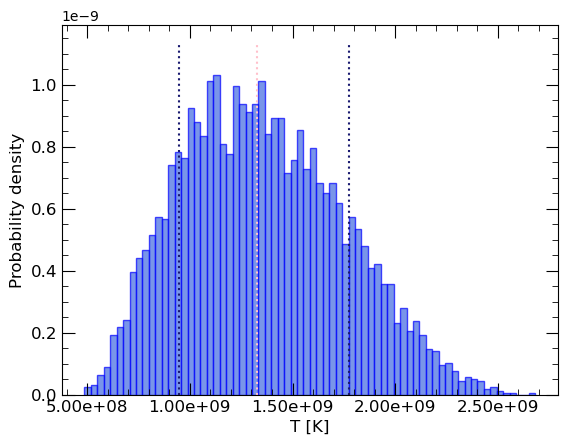

Median = 1326463804.477469 ; Lower limit =  947717845.9333459 ; Upper limit =  1773204483.9251502


In [21]:
T1 = Parallel(n_jobs=ncores, verbose=5)(delayed(Temp)(v1_ccm[i]) for i in range(niter))

median = np.nanpercentile(T1,50)
low_lim = np.nanpercentile(T1,perc_low)
high_lim = np.nanpercentile(T1,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(T1,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('T [K]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.2e'))
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
T1med = median
T1low = low_lim
T1up = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


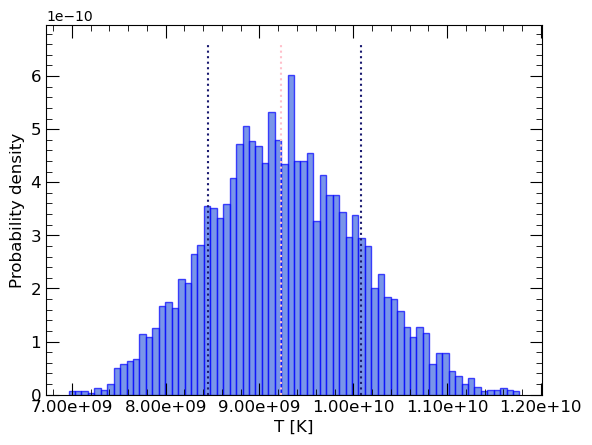

Median = 9227758226.627598 ; Lower limit =  8447993479.618767 ; Upper limit =  10078705114.934216


In [22]:
T3 = Parallel(n_jobs=ncores, verbose=5)(delayed(Temp)(v3_ccm[i]) for i in range(niter))

median = np.nanpercentile(T3,50)
low_lim = np.nanpercentile(T3,perc_low)
high_lim = np.nanpercentile(T3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(T3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('T [K]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.2e'))
#plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
T3med = median
T3low = low_lim
T3up = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


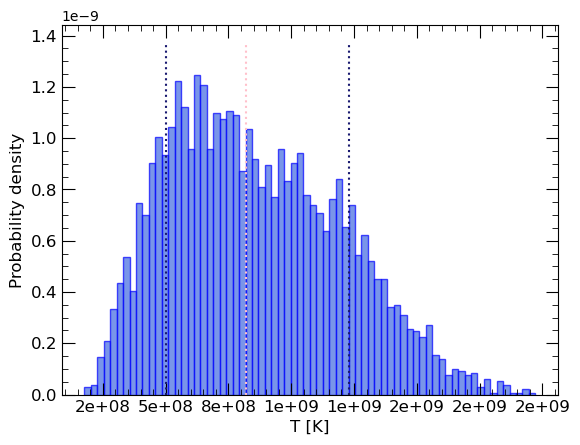

Median = 820966409.6938741 ; Lower limit =  503036320.8771756 ; Upper limit =  1231209300.6962569


In [23]:
Tvel = Parallel(n_jobs=ncores, verbose=5)(delayed(Temp)(vel[i]) for i in range(niter))

median = np.nanpercentile(Tvel,50)
low_lim = np.nanpercentile(Tvel,perc_low)
high_lim = np.nanpercentile(Tvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(Tvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('T [K]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%1.e'))
#plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
Tvelmed = median
Tvellow = low_lim
Tvelup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


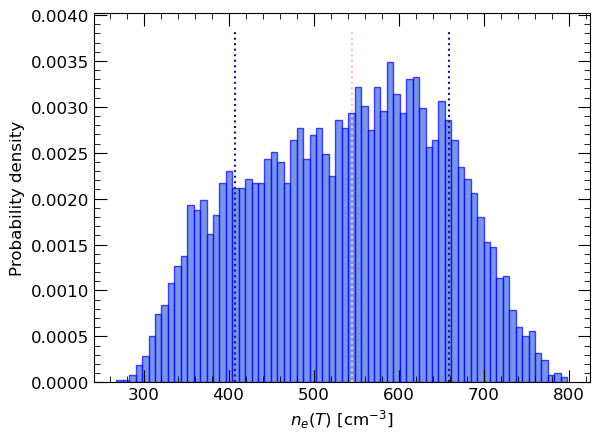

Median = 545.7267864970423 ; Lower limit =  408.05049209019063 ; Upper limit =  658.7240670108023
Median = 136.43169662426058 ; Lower limit =  102.01262302254766 ; Upper limit =  164.68101675270057


In [24]:
neD_new1 = Parallel(n_jobs=ncores, verbose=5)(delayed(necone)(FDrand[i], d10*10, dcm, hcmrand[i], T1[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neD_new1,50)
low_lim = np.nanpercentile(neD_new1,perc_low)
high_lim = np.nanpercentile(neD_new1,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neD_new1,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Median =',median/4,'; Lower limit = ',low_lim/4,'; Upper limit = ',high_lim/4)
neDmed_new1 = median
neDlow_new1 = low_lim
neDup_new1 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


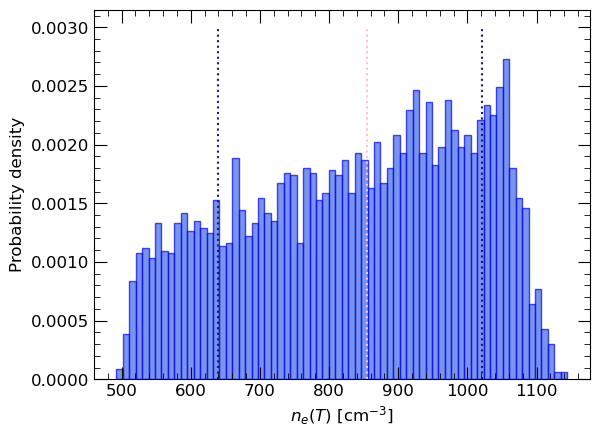

Median = 855.1233595101862 ; Lower limit =  639.2809715208872 ; Upper limit =  1021.3493681552267
Median = 213.78083987754655 ; Lower limit =  159.8202428802218 ; Upper limit =  255.33734203880667


In [25]:
neD_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(necone)(FDrand[i], d10*10, dcm, hcmrand[i], T3[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neD_new3,50)
low_lim = np.nanpercentile(neD_new3,perc_low)
high_lim = np.nanpercentile(neD_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neD_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Median =',median/4,'; Lower limit = ',low_lim/4,'; Upper limit = ',high_lim/4)
neDmed_new3 = median
neDlow_new3 = low_lim
neDup_new3 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


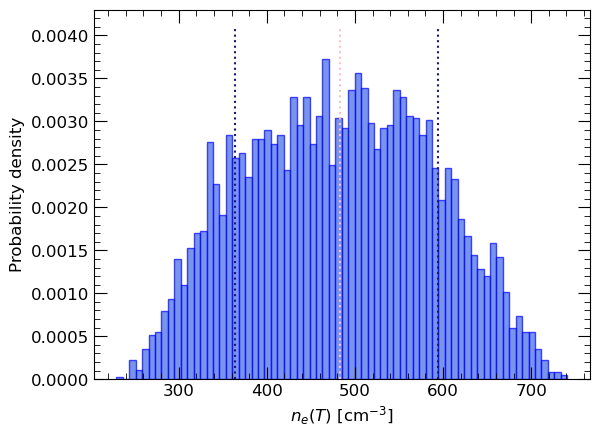

Median = 482.5929203295493 ; Lower limit =  363.6462680642297 ; Upper limit =  593.7949041837317
Median = 120.64823008238733 ; Lower limit =  90.91156701605742 ; Upper limit =  148.44872604593291


In [26]:
neD_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(necone)(FDrand[i], d10*10, dcm, hcmrand[i], Tvel[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neD_newvel,50)
low_lim = np.nanpercentile(neD_newvel,perc_low)
high_lim = np.nanpercentile(neD_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neD_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Median =',median/4,'; Lower limit = ',low_lim/4,'; Upper limit = ',high_lim/4)
neDmed_newvel = median
neDlow_newvel = low_lim
neDup_newvel = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


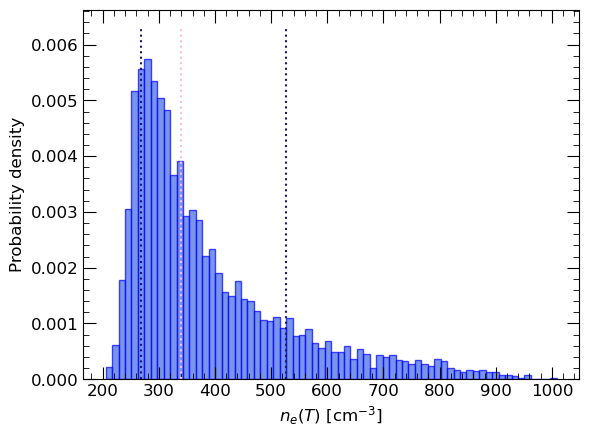

Median = 338.8864934941786 ; Lower limit =  268.5981122084083 ; Upper limit =  526.4718989095251
Median = 84.72162337354465 ; Lower limit =  67.14952805210207 ; Upper limit =  131.61797472738127


In [27]:
neE_new1 = Parallel(n_jobs=ncores, verbose=5)(delayed(neuv)(FErand[i], d10*10, bmaj, DRErand[i], T1[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neE_new1,50)
low_lim = np.nanpercentile(neE_new1,perc_low)
high_lim = np.nanpercentile(neE_new1,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neE_new1,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Median =',median/4,'; Lower limit = ',low_lim/4,'; Upper limit = ',high_lim/4)
neEmed_new1 = median
neElow_new1 = low_lim
neEup_new1 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


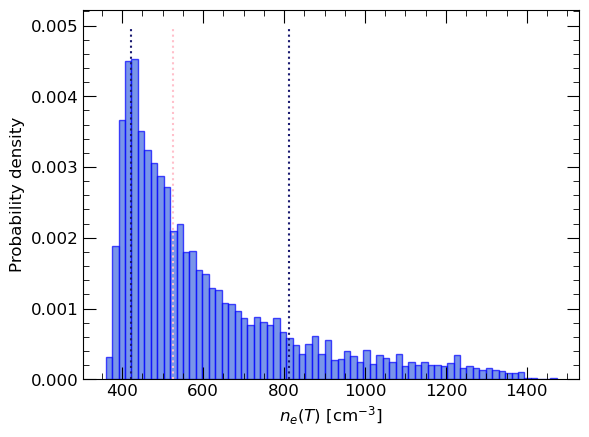

Median = 526.1938535552822 ; Lower limit =  421.7720979585348 ; Upper limit =  811.2977639583698
Median = 131.54846338882055 ; Lower limit =  105.4430244896337 ; Upper limit =  202.82444098959246


In [28]:
neE_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(neuv)(FErand[i], d10*10, bmaj, DRErand[i], T3[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neE_new3,50)
low_lim = np.nanpercentile(neE_new3,perc_low)
high_lim = np.nanpercentile(neE_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neE_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Median =',median/4,'; Lower limit = ',low_lim/4,'; Upper limit = ',high_lim/4)
neEmed_new3 = median
neElow_new3 = low_lim
neEup_new3 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


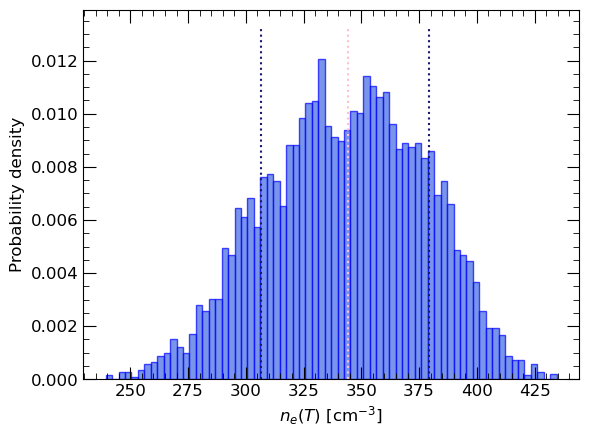

Median = 344.28647781015627 ; Lower limit =  306.73470667681687 ; Upper limit =  379.1340153293544
Median = 86.07161945253907 ; Lower limit =  76.68367666920422 ; Upper limit =  94.7835038323386


In [29]:
neE_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(necone)(FErand[i], d10*10, dcm, hcmrand[i], Tvel[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neE_newvel,50)
low_lim = np.nanpercentile(neE_newvel,perc_low)
high_lim = np.nanpercentile(neE_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neE_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Median =',median/4,'; Lower limit = ',low_lim/4,'; Upper limit = ',high_lim/4)
neEmed_newvel = median
neElow_newvel = low_lim
neEup_newvel = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


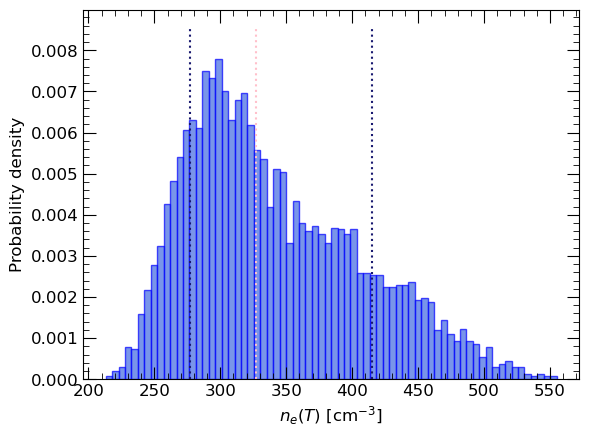

Median = 326.72260739565047 ; Lower limit =  276.8282069239124 ; Upper limit =  414.9004767066761
Median = 81.68065184891262 ; Lower limit =  69.2070517309781 ; Upper limit =  103.72511917666903


In [30]:
neC_new1 = Parallel(n_jobs=ncores, verbose=5)(delayed(neuv)(FCrand[i], d10*10, bmaj, DRCrand[i], T1[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neC_new1,50)
low_lim = np.nanpercentile(neC_new1,perc_low)
high_lim = np.nanpercentile(neC_new1,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neC_new1,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Median =',median/4,'; Lower limit = ',low_lim/4,'; Upper limit = ',high_lim/4)
neCmed_new1 = median
neClow_new1 = low_lim
neCup_new1 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


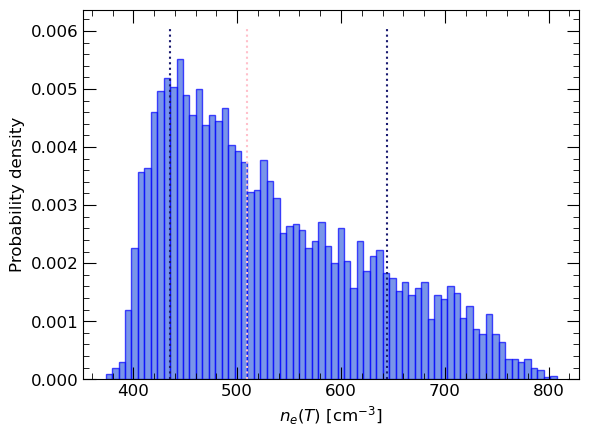

Median = 509.5928174799491 ; Lower limit =  435.2777017874626 ; Upper limit =  644.0464859375252
Median = 127.39820436998727 ; Lower limit =  108.81942544686565 ; Upper limit =  161.0116214843813


In [31]:
neC_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(neuv)(FCrand[i], d10*10, bmaj, DRCrand[i], T3[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neC_new3,50)
low_lim = np.nanpercentile(neC_new3,perc_low)
high_lim = np.nanpercentile(neC_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neC_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Median =',median/4,'; Lower limit = ',low_lim/4,'; Upper limit = ',high_lim/4)
neCmed_new3 = median
neClow_new3 = low_lim
neCup_new3 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


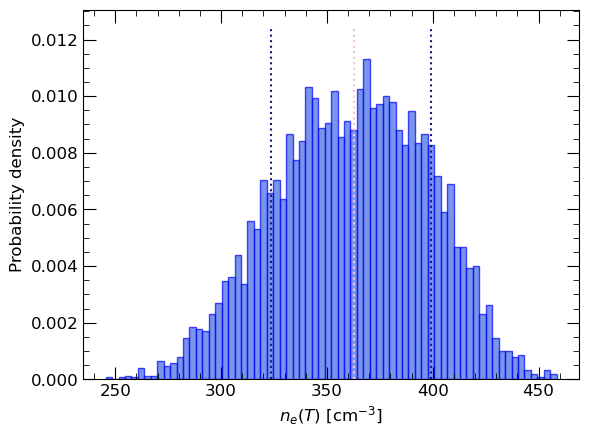

Median = 362.95579774934197 ; Lower limit =  323.5998283072667 ; Upper limit =  399.12511335553035
Median = 90.73894943733549 ; Lower limit =  80.89995707681668 ; Upper limit =  99.78127833888259


In [32]:
neC_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(necone)(FCrand[i], d10*10, dcm, hcmrand[i], Tvel[i], nu, Z) for i in range(niter))

median = np.nanpercentile(neC_newvel,50)
low_lim = np.nanpercentile(neC_newvel,perc_low)
high_lim = np.nanpercentile(neC_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(neC_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Median =',median/4,'; Lower limit = ',low_lim/4,'; Upper limit = ',high_lim/4)
neCmed_newvel = median
neClow_newvel = low_lim
neCup_newvel = high_lim

### Lobe distance estimate

In [33]:
disnorth = 1.200302*60 
dissouth = 1.575077*60    # both arcsec
dispcNpro = disnorth*0.048*d10   
dispcSpro = dissouth*0.048*d10   # both in parsec
dispcN = dispcNpro/np.sin(incl*np.pi/180)
dispcS = dispcSpro/np.sin(incl*np.pi/180)  # both in parsec and corrected for the inclination of the source
dispcNmin = dispcNpro/np.sin((incl+eincl)*np.pi/180)
dispcSmin = dispcSpro/np.sin((incl+90+eincl)*np.pi/180) 
dispcNmax = dispcNpro/np.sin((incl-eincl)*np.pi/180)
dispcSmax = dispcSpro/np.sin((incl+90-eincl)*np.pi/180)  
print('Core - north lobe projected separation in arcsec:', disnorth)
print('Core - south lobe projected separation in arcsec:', dissouth)
print('Core - north lobe de-projected separation in pc:', dispcN)
print('Core - south lobe de-projected separation in pc:', abs(dispcS))

Core - north lobe projected separation in arcsec: 72.01812
Core - south lobe projected separation in arcsec: 94.50462
Core - north lobe de-projected separation in pc: 3.3595621868736276
Core - south lobe de-projected separation in pc: 4.4085314617607505


In [34]:
print(dispcNmax-dispcN, dispcN-dispcNmin)
print(dispcSmax-dispcS, dispcS-dispcSmin)

0.06840256819015522 0.06178689990075137
3.0778830070595795 -4.0845724648898205


### Jet age estimate

The jet age can be estimated using:

$$ t = \dfrac{3L_j}{5\dot{L_j}}$$

In [35]:
def age(distcm, vcm):
    distcm = abs(distcm)
    tsec = (3/5)*(distcm/vcm)
    tkyr = tsec/(365*24*60*60)/1e3
    return tkyr

tmaxN = age(dispcN*pc, vmin)
tminN = age(dispcN*pc, vmax)
tmaxS = age(dispcS*pc, vmin)
tminS = age(dispcS*pc, vmax)
print('Max jet age in kyrs (north lobe)', tmaxN)
print('Min jet age in kyrs (north lobe)', tminN)
print('\n')
print('Max jet age in kyrs (south lobe)', tmaxS)
print('Min jet age in kyrs (south lobe)', tminS)

Max jet age in kyrs (north lobe) 94.03782235179233
Min jet age in kyrs (north lobe) 5.429276204881351


Max jet age in kyrs (south lobe) 123.3996203592046
Min jet age in kyrs (south lobe) 7.12448040322844


### CM-based estimate for the jet age

In [36]:
def diff(a,b):
    return abs(a-b)

In [37]:
#disNrand = np.random.normal(np.mean([dispcNmin, dispcNmax]), np.std([dispcNmin, dispcNmax]), niter)
#disSrand = np.random.normal(np.mean([dispcSmin, dispcNmax]), np.std([dispcSmin, dispcSmax]), niter)
#vmean = np.mean([vmin,vmax])
#vstd = np.std([vmin,vmax])
#vrand = np.random.normal(vmean, vstd, niter)

disNrand = np.random.uniform(dispcNmin, dispcNmax, niter)
disSrand = np.random.uniform(dispcSmin, dispcNmax, niter)
vrand = np.random.uniform(vmin, vmax, niter)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


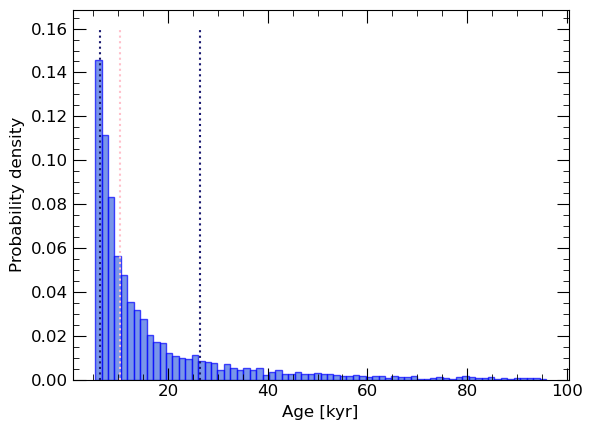

Median = 10286.519850568886 ; Lower limit =  6401.828563476862 ; Upper limit =  26348.437542904434


In [38]:
tN = Parallel(n_jobs=ncores, verbose=5)(delayed(age)(disNrand[i]*pc, vrand[i]) for i in range(niter))

median = np.nanpercentile(tN,50)
low_lim = np.nanpercentile(tN,perc_low)
high_lim = np.nanpercentile(tN,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(tN,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [kyr]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
tNmed = median
tNlow = low_lim
tNup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


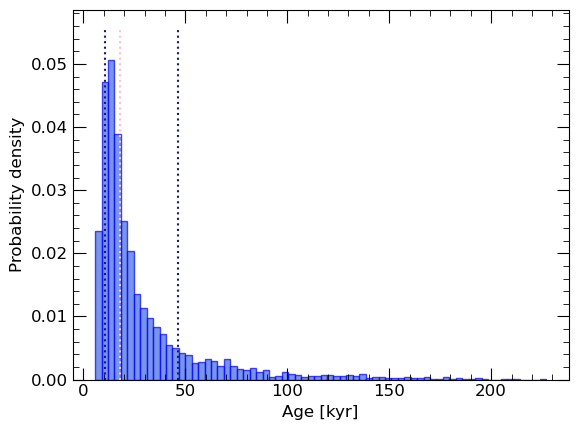

Median = 18094.229437955826 ; Lower limit =  10781.56709349325 ; Upper limit =  46157.45603129847


In [39]:
tS= Parallel(n_jobs=ncores, verbose=5)(delayed(age)(disSrand[i]*pc, vrand[i]) for i in range(niter))

median = np.nanpercentile(tS,50)
low_lim = np.nanpercentile(tS,perc_low)
high_lim = np.nanpercentile(tS,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(tS,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [kyr]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
tSmed = median
tSlow = low_lim
tSup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


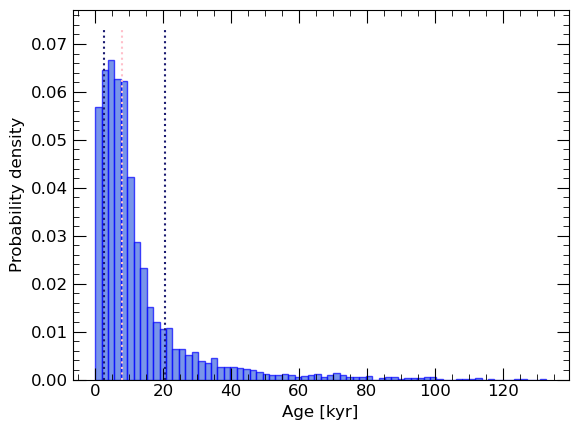

Median = 7947.5236787068 ; Lower limit =  2807.986435070226 ; Upper limit =  20566.04321527484


In [40]:
diff_cons = Parallel(n_jobs=ncores, verbose=5)(delayed(diff)(tS[i], tN[i]) for i in range(niter))

median = np.nanpercentile(diff_cons,50)
low_lim = np.nanpercentile(diff_cons,perc_low)
high_lim = np.nanpercentile(diff_cons,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(diff_cons,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [kyr]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
diff_consmed = median
diff_conslow = low_lim
diff_consup = high_lim

### CM-based for the jet age (new estimate for the velocity)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


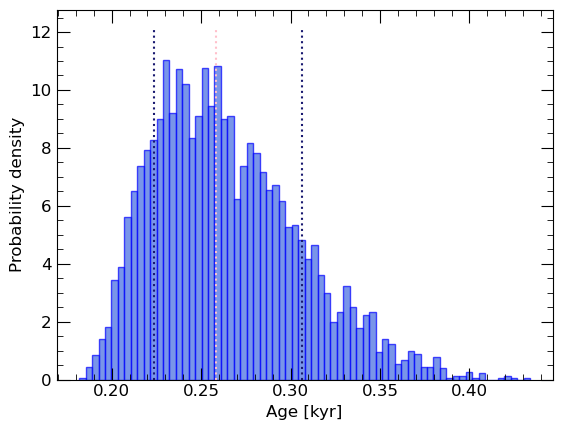

Median = 258.5081717718204 ; Lower limit =  223.7815079297164 ; Upper limit =  306.1615027763809


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


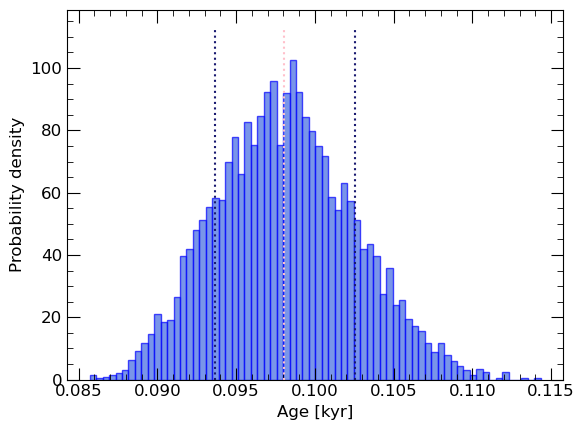

Median = 98.0410419180652 ; Lower limit =  93.65611120382894 ; Upper limit =  102.56559699199859


In [41]:
tN_new = Parallel(n_jobs=ncores, verbose=5)(delayed(age)(disNrand[i]*pc, v1_ccm[i]) for i in range(niter))

median = np.nanpercentile(tN_new,50)
low_lim = np.nanpercentile(tN_new,perc_low)
high_lim = np.nanpercentile(tN_new,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(tN_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [kyr]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
tNmed_new = median
tNlow_new = low_lim
tNup_new = high_lim

tN_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(age)(disNrand[i]*pc, v3_ccm[i]) for i in range(niter))

median = np.nanpercentile(tN_new3,50)
low_lim = np.nanpercentile(tN_new3,perc_low)
high_lim = np.nanpercentile(tN_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(tN_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [kyr]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
tNmed_new3 = median
tNlow_new3 = low_lim
tNup_new3 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


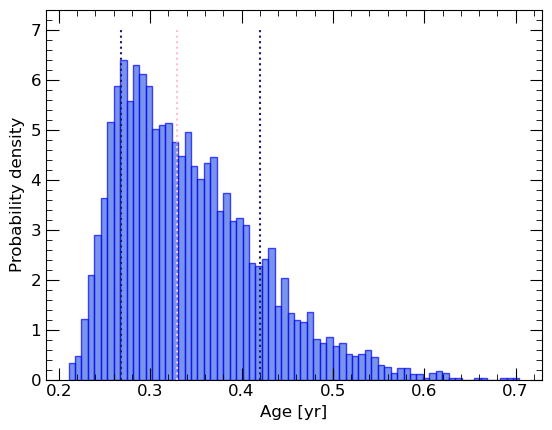

Median = 328.8824739446276 ; Lower limit =  268.30795549379667 ; Upper limit =  420.1775886736539


In [42]:
tN_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(age)(disNrand[i]*pc, vel[i]) for i in range(niter))

median = np.nanpercentile(tN_newvel,50)
low_lim = np.nanpercentile(tN_newvel,perc_low)
high_lim = np.nanpercentile(tN_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(tN_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [yr]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
tNmed_newvel = median
tNlow_newvel = low_lim
tNup_newvel = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


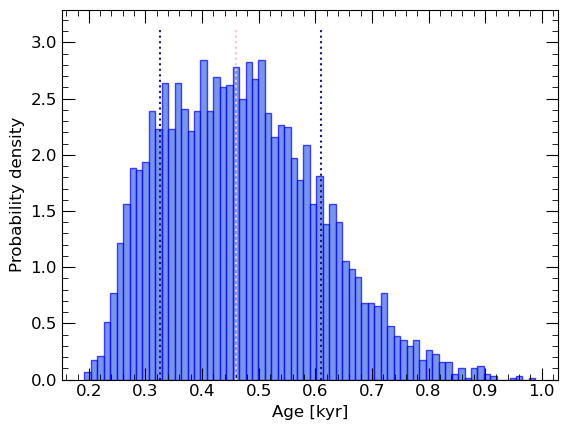

Median = 459.75418269460897 ; Lower limit =  325.0324213896702 ; Upper limit =  610.3298643263566


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


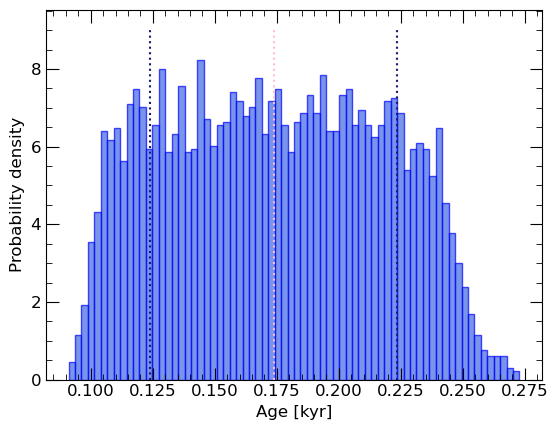

Median = 173.92978682910808 ; Lower limit =  123.84108943270219 ; Upper limit =  223.52888615844574


In [43]:
tS_new = Parallel(n_jobs=ncores, verbose=5)(delayed(age)(disSrand[i]*pc, v1_ccm[i]) for i in range(niter))

median = np.nanpercentile(tS_new,50)
low_lim = np.nanpercentile(tS_new,perc_low)
high_lim = np.nanpercentile(tS_new,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(tS_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [kyr]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
tSmed_new = median
tSlow_new = low_lim
tSup_new = high_lim

tS_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(age)(disSrand[i]*pc, v3_ccm[i]) for i in range(niter))

median = np.nanpercentile(tS_new3,50)
low_lim = np.nanpercentile(tS_new3,perc_low)
high_lim = np.nanpercentile(tS_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(tS_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [kyr]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
tNSed_new3 = median
tSlow_new3 = low_lim
tSup_new3 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


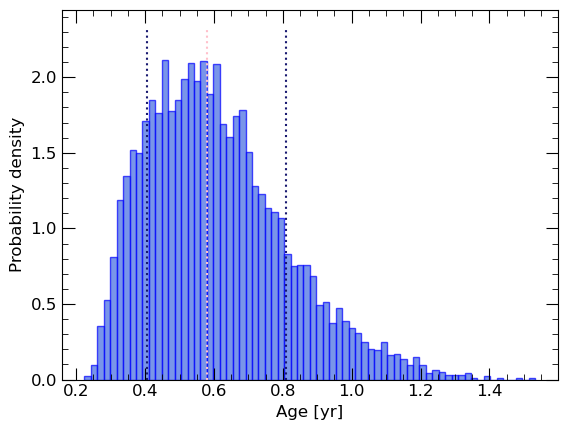

Median = 580.7518266641529 ; Lower limit =  406.09004260270723 ; Upper limit =  808.0930065396897


In [44]:
tS_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(age)(disSrand[i]*pc, vel[i]) for i in range(niter))

median = np.nanpercentile(tS_newvel,50)
low_lim = np.nanpercentile(tS_newvel,perc_low)
high_lim = np.nanpercentile(tS_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(tS_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [yr]', fontsize=12)
#plt.xlim(0,10000)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
tSmed_newvel = median
tSlow_newvel = low_lim
tSup_newvel = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


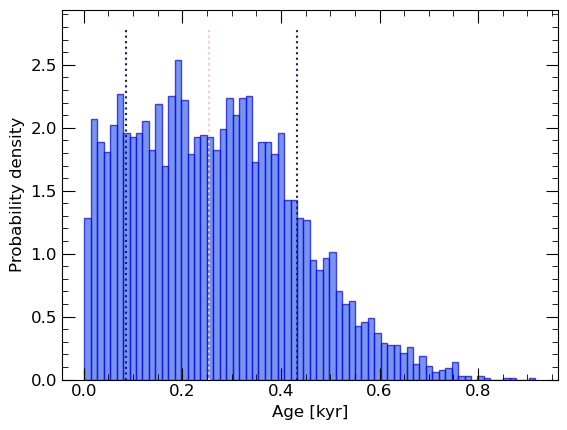

Median = 253.97224267855844 ; Lower limit =  85.78370592993686 ; Upper limit =  433.0477095963779


In [45]:
diff_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(diff)(tS_newvel[i], tN_newvel[i]) for i in range(niter))

median = np.nanpercentile(diff_newvel,50)
low_lim = np.nanpercentile(diff_newvel,perc_low)
high_lim = np.nanpercentile(diff_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(diff_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('Age [kyr]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median*1e3,'; Lower limit = ',low_lim*1e3,'; Upper limit = ',high_lim*1e3)
diff_newvelmed = median
diff_newvellow = low_lim
diff_newvelup = high_lim

### Lobe's distances estimate

In [46]:
disnorth = 1.200302*60 
dissouth = 1.575077*60    # both arcsec
dispcNpro = disnorth*0.048*d10   
dispcSpro = dissouth*0.048*d10   # both in parsec
dispcN = dispcNpro/np.sin(incl*np.pi/180)
dispcS = dispcSpro/np.sin(incl*np.pi/180)  # both in parsec and corrected for the inclination of the source
dispcNmin = dispcNpro/np.sin((incl+eincl)*np.pi/180)
dispcSmin = dispcSpro/np.sin((incl+eincl)*np.pi/180) 
dispcNmax = dispcNpro/np.sin((incl-eincl)*np.pi/180)
dispcSmax = dispcSpro/np.sin((incl-eincl)*np.pi/180)  
print('Core - north lobe projected separation in arcsec:', disnorth)
print('Core - south lobe projected separation in arcsec:', dissouth)
print('Core - north lobe de-projected separation in pc:', dispcN)
print('Core - south lobe de-projected separation in pc:', abs(dispcS))

Core - north lobe projected separation in arcsec: 72.01812
Core - south lobe projected separation in arcsec: 94.50462
Core - north lobe de-projected separation in pc: 3.3595621868736276
Core - south lobe de-projected separation in pc: 4.4085314617607505


### Jet Power (and pressure) estimate

$$ Q_{jet} = Q_0 = \left(\dfrac{5}{3}\right)^3\frac{\rho_0}{C_1^5}L_{jet}^2\dot{L_{jet}}^3$$

where:

$$ \dot{L_{jet}} = \sqrt{\dfrac{16k_b}{3m_p}T}$$

$C_1$ is a dimensionless constant that depends on the thermodybnamical properties of the jet material, and on the aspect ratio, R of the lobe inflates by the jet (is the length of the lobe divided by its width). The explicit form is the following:
$$C_1 = \left(\dfrac{C_2}{C_3\theta^2}\dfrac{(\Gamma_x+1)(\Gamma_c-1)(5-\beta)}{18[9{\Gamma_c+(\Gamma_c-1)\frac{C_2}{4\theta^2}-4-\beta}]}\right)^{\frac{1}{5-\beta}}$$
with
$$C_2 = \left(\dfrac{(\Gamma_c-1)(\Gamma_j-1)}{4\Gamma_c}+1\right)^{\frac{\Gamma_c}{\Gamma_c-1}}\left(\dfrac{\Gamma_j+1}{\Gamma_j-1}\right)$$
$$C_3 = \dfrac{\pi}{R_{ax}^2}$$

also the pressure inside the lobe is given by:

$$ p = 0.0675\dfrac{C_1^{10/3}}{R_{ax}^2}\left(\dfrac{\rho_0Q_0^2}{L_j^4}\right)^{1/3}$$

where $Rax$ is the axial ratio, meaning the length of the lobe divided by its width

In [47]:
vmin = np.sqrt((16*kb*Tmin)/(3*mh))
vmax = np.sqrt((16*kb*Tmax)/(3*mh))  # Both in cm/s

# Constant C1 and others --> copied from GRS 1915+105
Gammac = 5/3                            # Adiabatic index of the material in the cavity, -- ASSUMED 
Gammax = 5/3                            # Adiabatic index of the material in the external medium, -- ASSUMED 
Gammaj = 5/3                            # Adiabatic index of the material in the jet, -- ASSUMED 

def C_cons(g_c,g_j,g_x,ope):
    beta = 0                                # density profile index (beta = 0 for a uniform density medium), -- ASSUMED 
    theta_ra = ope*np.pi/180                # Jet opening angle, in radiants
    C2_0 = (((g_c-1)*(g_j-1))/(4*g_c) + 1 )**(g_c/(g_c-1)) * ((g_j+1)/(g_j-1))
    Rax_0 = np.sqrt((1/4*(C2_0/theta_ra**2))) # axial ratio of the jet-blown cavity                         
    C3_0 = np.pi/(4*Rax_0**2)
    C1_0 = ((C2_0)/(C3_0*theta_ra**2)*((g_x+1)*(g_c-1)*(5-beta)**3)/(18*(9*(g_c + (g_c -1)*(C2_0/(4*theta_ra**2))) - 4 - beta)) )**(1/(5-beta))
    return C1_0

def RAX(g_c,g_j,g_x,ope):
    beta = 0                                # density profile index (beta = 0 for a uniform density medium), -- ASSUMED 
    theta_ra = ope*np.pi/180                # Jet opening angle, in radiants
    C2_0 = (((g_c-1)*(g_j-1))/(4*g_c) + 1 )**(g_c/(g_c-1)) * ((g_j+1)/(g_j-1))
    Rax_0 = np.sqrt((1/4*(C2_0/theta_ra**2))) 
    return Rax_0

wnorth = 11  # arcsec, roughly
wsouth = 10  # arcsec, roughly
wpcNpro = wnorth*0.048*d10   
wpcSpro = wsouth*0.048*d10   # both in parsec
wpcN = wpcNpro#/np.sin(incl*np.pi/180)
wpcS = wpcSpro#/np.sin(-incl*np.pi/180)  # both in parsec 
opeangleN = np.arctan(wnorth/disnorth)
opeangleS = np.arctan(wsouth/dissouth)
opedegN = (opeangleN*180)/np.pi
opedegS = (opeangleS*180)/np.pi
print('North lobe opening angle estimate [degree]: ~', opedegN)
print('South lobe opening angle estimate [degree]: ~', opedegS)

North lobe opening angle estimate [degree]: ~ 8.684202387659019
South lobe opening angle estimate [degree]: ~ 6.04027206398686


### CM-based estimate of the pseudo-constant C1 and axial-ratio of the jet-blown cavity $R_{ax}$ 

In [48]:
ope_rand = np.random.uniform(1,10,niter)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


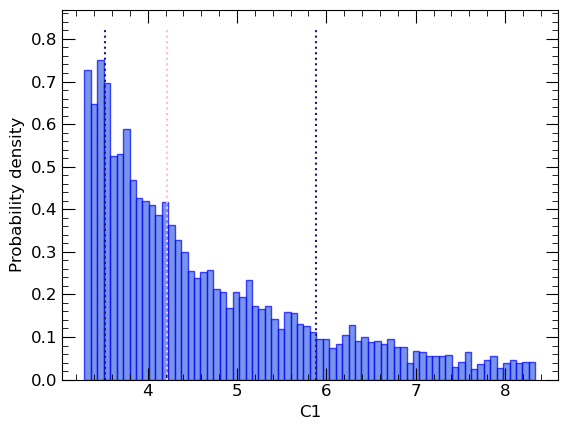

Median = 4.220228029517008 ; Lower limit =  3.518719729491454 ; Upper limit =  5.8831519950543285


In [49]:
C1 = Parallel(n_jobs=ncores, verbose=5)(delayed(C_cons)(Gammac, Gammaj, Gammax, ope_rand[i]) for i in range(niter))

median = np.nanpercentile(C1,50)
low_lim = np.nanpercentile(C1,perc_low)
high_lim = np.nanpercentile(C1,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(C1,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('C1', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
C1med = median
C1low = low_lim
C1up = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


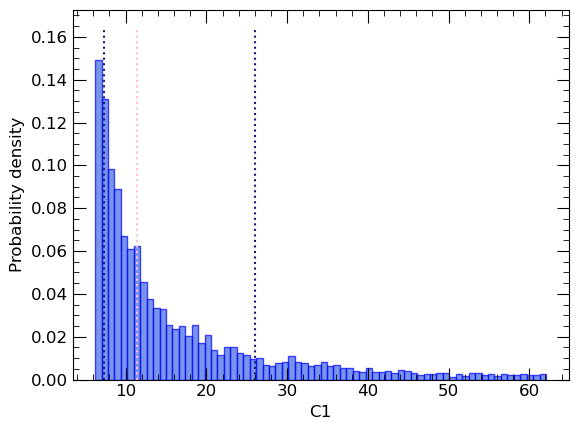

Median = 11.382148086906081 ; Lower limit =  7.297020181247011 ; Upper limit =  25.968555888778663


In [50]:
Rax = Parallel(n_jobs=ncores, verbose=5)(delayed(RAX)(Gammac, Gammaj, Gammax, ope_rand[i]) for i in range(niter))

median = np.nanpercentile(Rax,50)
low_lim = np.nanpercentile(Rax,perc_low)
high_lim = np.nanpercentile(Rax,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(Rax,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('C1', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
Raxmed = median
Raxlow = low_lim
Raxup = high_lim

In [51]:
Con1_n = C_cons(Gammac, Gammaj, Gammax, opedegN)
Con1_s = C_cons(Gammac, Gammaj, Gammax, opedegS)

def power(ne, dislobe, vcm, Con1, incl):
    rho = ne*1.370*mh
    rho0 = rho/4
    dislobecm = dislobe*pc/np.sin((incl*np.pi)/180)
    Qjet = (5/3)**3*(rho0/(Con1)**5)*dislobecm**2*vcm**3

    return Qjet

def pressure(ne, Q0, dislobe, R, Con1):
    rho = ne*1.370*mh
    rho0 = rho/4
    dislobecm = dislobe*pc
    #R = dislobe/wlobe
    press = 0.0675*((Con1**(10/3))/R**2)*((rho0*(Q0)**2)/dislobecm**4)**(1/3)

    return press

QminD = power(neminD, dispcS, vmin, Con1_s, incl)
QmaxD = power(nemaxD, dispcS, vmax, Con1_s, incl)
pminD = pressure(neminD, QminD, dispcS, wpcS, Con1_s)
pmaxD = pressure(nemaxD, QmaxD, dispcS, wpcS, Con1_s)
print('Min transferred energy using D region [erg/s]:', QminD)
print('Max transferred energy using D region [erg/s]:', QmaxD)
print('Min pressure using D region [erg/cm3]:', pminD)
print('Max pressure using D region [erg/cm3]:', pmaxD)
print('\n')
QminE = power(neminE, dispcS, vmin, Con1_s, incl)
QmaxE = power(nemaxE, dispcS, vmax, Con1_s, incl)
pminE = pressure(neminE, QminE, dispcS, wpcS, Con1_s)
pmaxE = pressure(nemaxE, QmaxE, dispcS, wpcS, Con1_s)
print('Min transferred energy using E region [erg/s]:', QminE)
print('Max transferred energy using E region [erg/s]:', QmaxE)
print('Min pressure using E region [erg/cm3]:', pminE)
print('Max pressure using E region [erg/cm3]:', pmaxE)
print('\n')
QminC = power(neminC, dispcN, vmin, Con1_n, incl)
QmaxC = power(nemaxC, dispcN, vmax, Con1_n, incl)
pminC = pressure(neminC, QminC, dispcN, wpcN, Con1_n)
pmaxC = pressure(nemaxC, QmaxC, dispcN, wpcN, Con1_n)
print('Min transferred energy using C region [erg/s]:', QminC)
print('Max transferred energy using C region [erg/s]:', QmaxC)
print('Min pressure using C region [erg/cm3]:', pminC)
print('Max pressure using C region [erg/cm3]:', pmaxC)

Min transferred energy using D region [erg/s]: 3.1533901184590605e+32
Max transferred energy using D region [erg/s]: 5.383790015326048e+36
Min pressure using D region [erg/cm3]: 1.968325020710322e-10
Max pressure using D region [erg/cm3]: 1.940200428171059e-07


Min transferred energy using E region [erg/s]: 1.4588523488320366e+32
Max transferred energy using E region [erg/s]: 2.4907018841407708e+36
Min pressure using E region [erg/cm3]: 9.106058787078679e-11
Max pressure using E region [erg/cm3]: 8.975946031141278e-08


Min transferred energy using C region [erg/s]: 1.7160603430469365e+32
Max transferred energy using C region [erg/s]: 2.929833669012634e+36
Min pressure using C region [erg/cm3]: 7.24293562501262e-11
Max pressure using C region [erg/cm3]: 7.139444275211013e-08


### CM-based $Q_{jet}$ and $p_{jet}$ estimate

In [52]:
incl_rand = np.random.uniform(incl-eincl, incl+eincl, niter)
C1_rand = np.random.uniform(C1low, C1up, niter)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


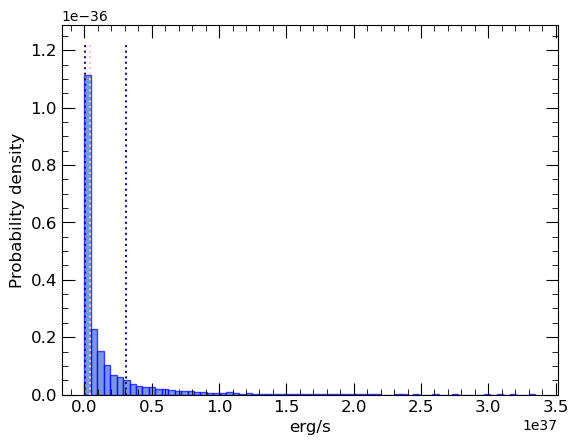

Median = 3.84260103382069e+35 ; Lower limit =  2.158927048702009e+34 ; Upper limit =  3.078127400254219e+36


In [53]:
QD = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neD[i], disSrand[i], vrand[i], C1[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QD,50)
low_lim = np.nanpercentile(QD,perc_low)
high_lim = np.nanpercentile(QD,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QD,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QDmed = median
QDlow = low_lim
QDup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


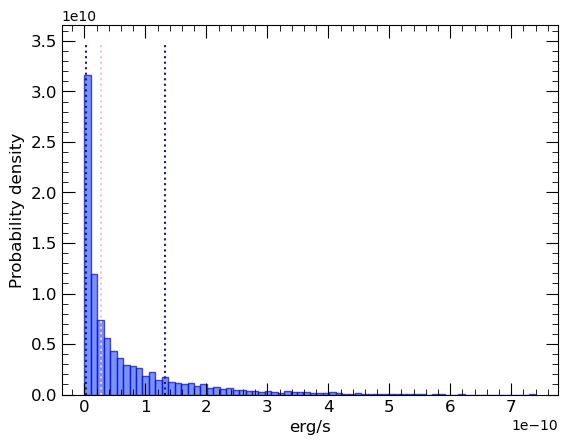

Median = 2.6372889289610953e-11 ; Lower limit =  3.0480230422725586e-12 ; Upper limit =  1.328995514716246e-10


In [54]:
pD = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neD[i], QD[i], disSrand[i], Rax[i], C1[i]) for i in range(niter))

median = np.nanpercentile(pD,50)
low_lim = np.nanpercentile(pD,perc_low)
high_lim = np.nanpercentile(pD,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pD,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pDmed = median
pDlow = low_lim
pDup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


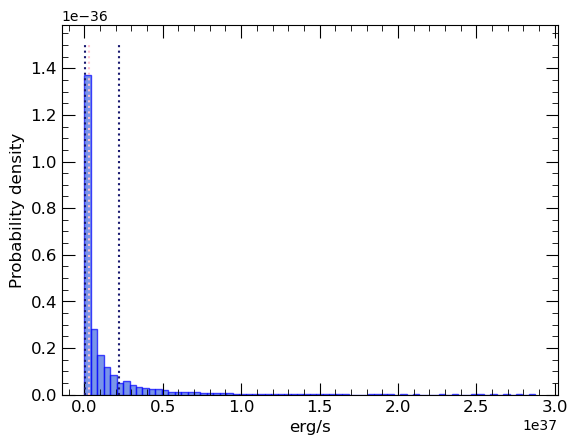

Median = 2.7369913660330418e+35 ; Lower limit =  1.44689011013035e+34 ; Upper limit =  2.2087072545112162e+36


In [55]:
QE = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neE[i], disSrand[i], vrand[i], C1[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QE,50)
low_lim = np.nanpercentile(QE,perc_low)
high_lim = np.nanpercentile(QE,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QE,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QEmed = median
QElow = low_lim
QEup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


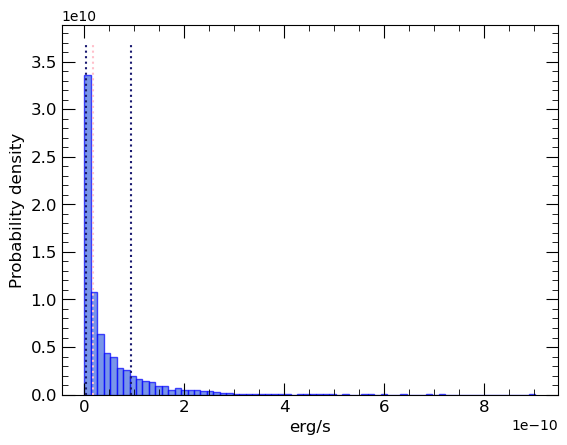

Median = 1.803181214272272e-11 ; Lower limit =  2.119662095314735e-12 ; Upper limit =  9.315459000415167e-11


In [56]:
pE = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neE[i], QE[i], disSrand[i], Rax[i], C1[i]) for i in range(niter))

median = np.nanpercentile(pE,50)
low_lim = np.nanpercentile(pE,perc_low)
high_lim = np.nanpercentile(pE,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pE,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pEmed = median
pElow = low_lim
pEup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


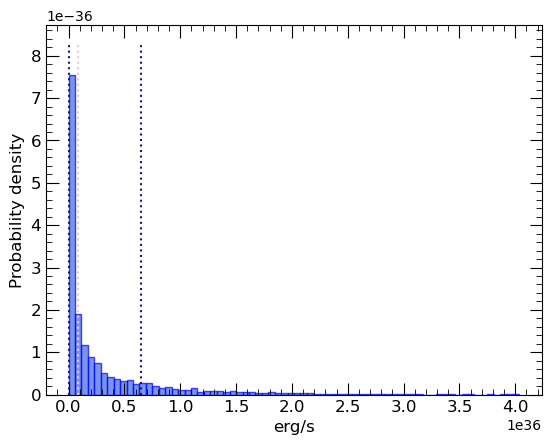

Median = 8.69406012361079e+34 ; Lower limit =  4.805952990566713e+33 ; Upper limit =  6.485372156030544e+35


In [57]:
QC = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neC[i], disNrand[i], vrand[i], C1[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QC,50)
low_lim = np.nanpercentile(QC,perc_low)
high_lim = np.nanpercentile(QC,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QC,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QCmed = median
QClow = low_lim
QCup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


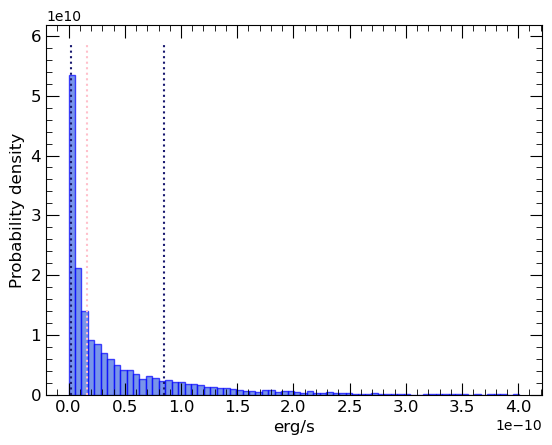

Median = 1.651936208544459e-11 ; Lower limit =  1.996997148791948e-12 ; Upper limit =  8.521238594685987e-11


In [58]:
pC = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neC[i], QC[i], disNrand[i], Rax[i], C1[i]) for i in range(niter))

median = np.nanpercentile(pC,50)
low_lim = np.nanpercentile(pC,perc_low)
high_lim = np.nanpercentile(pC,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pC,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pCmed = median
pClow = low_lim
pCup = high_lim

### CM-based $Q_{jet}$ and $p_{jet}$ estimate (new velocity estimate)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


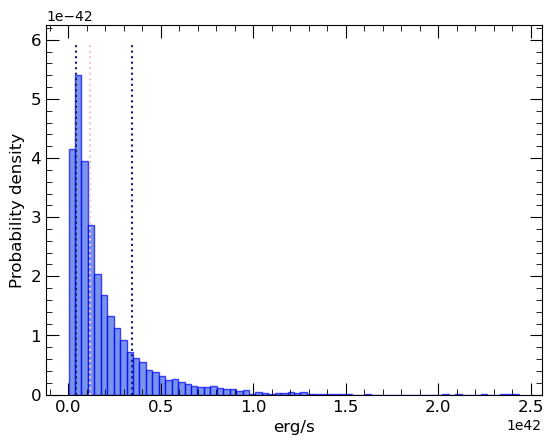

Median = 1.157846933929445e+41 ; Lower limit =  3.985588514544414e+40 ; Upper limit =  3.4638342876371872e+41


In [59]:
QD_new = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neD_new1[i], disSrand[i], v1_ccm[i], C1_rand[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QD_new,50)
low_lim = np.nanpercentile(QD_new,perc_low)
high_lim = np.nanpercentile(QD_new,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QD_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QDmed_new = median
QDlow_new = low_lim
QDup_new = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


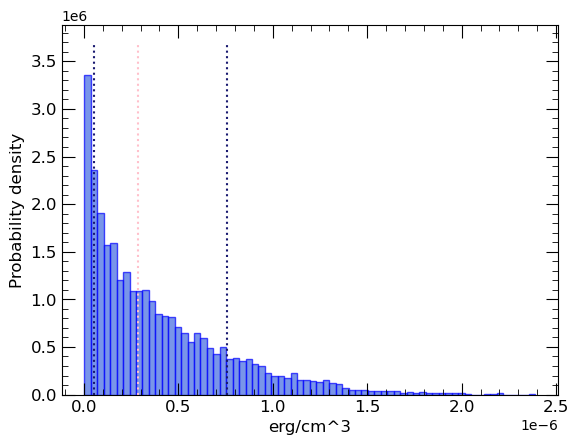

Median = 2.8764077669038787e-07 ; Lower limit =  5.4119147115962636e-08 ; Upper limit =  7.56061497987363e-07


In [60]:
pD_new = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neD_new1[i], QD_new[i], disSrand[i], Rax[i], C1_rand[i]) for i in range(niter))

median = np.nanpercentile(pD_new,50)
low_lim = np.nanpercentile(pD_new,perc_low)
high_lim = np.nanpercentile(pD_new,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pD_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/cm^3', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pDmed_new = median
pDlow_new = low_lim
pDup_new = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


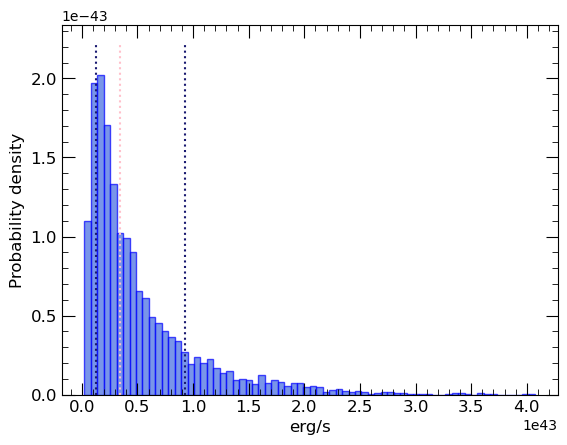

Median = 3.403107051255672e+42 ; Lower limit =  1.311939200215459e+42 ; Upper limit =  9.254424709531904e+42


In [61]:
QD_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neD_new3[i], disSrand[i], v3_ccm[i], C1_rand[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QD_new3,50)
low_lim = np.nanpercentile(QD_new3,perc_low)
high_lim = np.nanpercentile(QD_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QD_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QDmed_new3 = median
QDlow_new3 = low_lim
QDup_new3 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


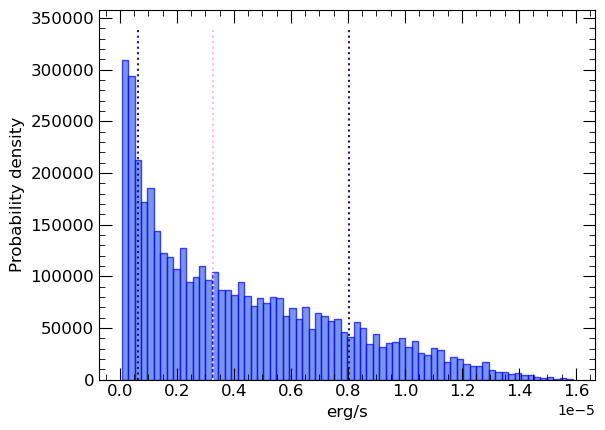

Median = 3.267662633083228e-06 ; Lower limit =  6.178508565436945e-07 ; Upper limit =  8.028715744137945e-06


In [62]:
pD_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neD_new3[i], QD_new3[i], disSrand[i], Rax[i], C1_rand[i]) for i in range(niter))

median = np.nanpercentile(pD_new3,50)
low_lim = np.nanpercentile(pD_new3,perc_low)
high_lim = np.nanpercentile(pD_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pD_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pDmed_new3 = median
pDlow_new3= low_lim
pDup_new3 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


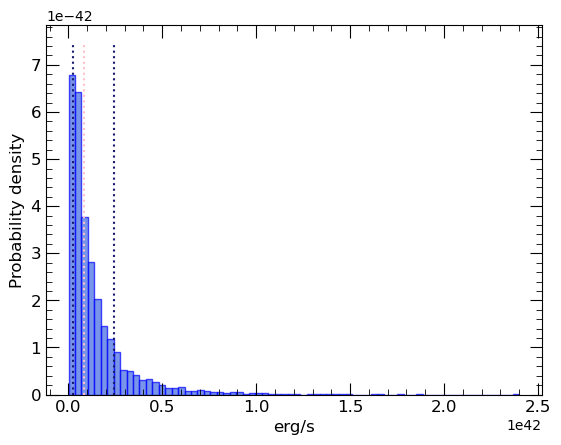

Median = 8.0789734420874e+40 ; Lower limit =  2.6968210857280887e+40 ; Upper limit =  2.431528035544515e+41


In [63]:
QE_new = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neE_new1[i], disSrand[i], v1_ccm[i], C1_rand[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QE_new,50)
low_lim = np.nanpercentile(QE_new,perc_low)
high_lim = np.nanpercentile(QE_new,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QE_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QEmed_new = median
QElow_new = low_lim
QEup_new = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


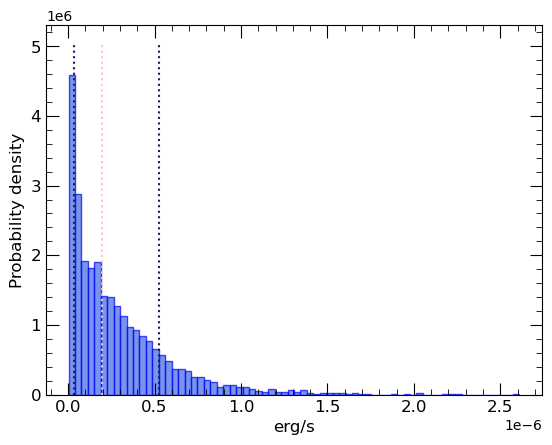

Median = 1.978785366903277e-07 ; Lower limit =  3.619876029755576e-08 ; Upper limit =  5.270393591611494e-07


In [64]:
pE_new = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neE_new1[i], QE_new[i], disSrand[i], Rax[i], C1_rand[i]) for i in range(niter))

median = np.nanpercentile(pE_new,50)
low_lim = np.nanpercentile(pE_new,perc_low)
high_lim = np.nanpercentile(pE_new,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pE_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pEmed_new = median
pElow_new = low_lim
pEup_new = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


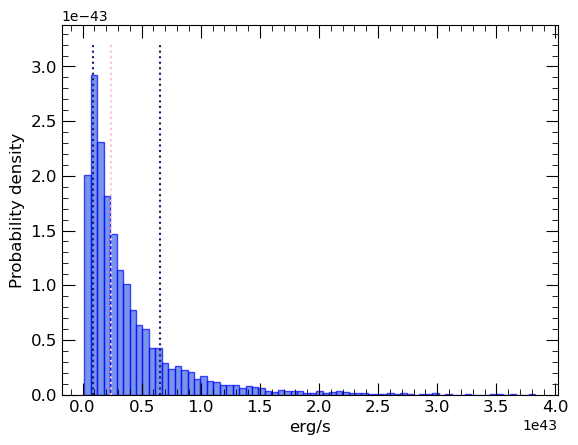

Median = 2.375813338461637e+42 ; Lower limit =  8.711501929816967e+41 ; Upper limit =  6.549650344303886e+42


In [65]:
QE_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neE_new3[i], disSrand[i], v3_ccm[i], C1_rand[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QE_new3,50)
low_lim = np.nanpercentile(QE_new3,perc_low)
high_lim = np.nanpercentile(QE_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QE_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QEmed_new3 = median
QElow_new3 = low_lim
QEup_new3 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


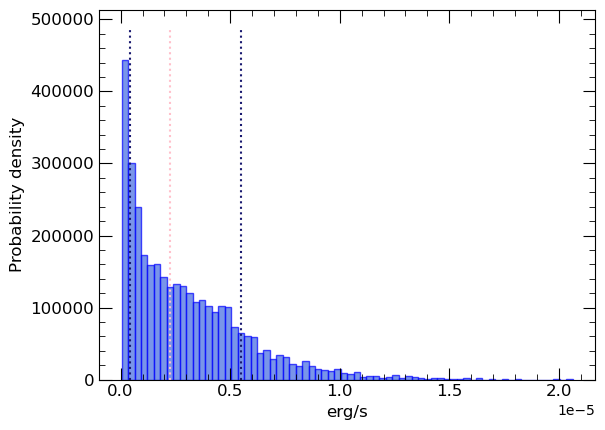

Median = 2.2733360423468134e-06 ; Lower limit =  4.3427580868063913e-07 ; Upper limit =  5.5047704768314885e-06


In [66]:
pE_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neE_new3[i], QE_new3[i], disSrand[i], Rax[i], C1_rand[i]) for i in range(niter))

median = np.nanpercentile(pE_new3,50)
low_lim = np.nanpercentile(pE_new3,perc_low)
high_lim = np.nanpercentile(pE_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pE_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pEmed_new = median
pElow_new = low_lim
pEup_new = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


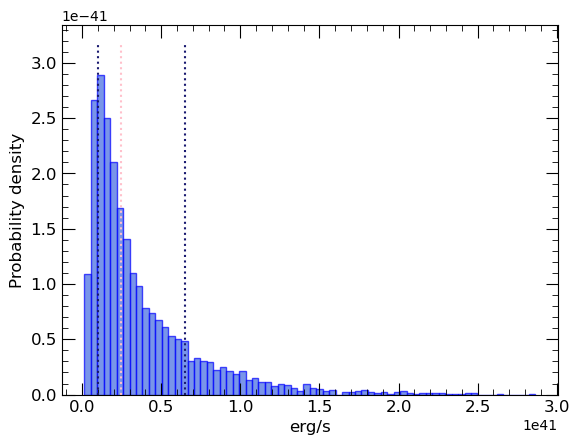

Median = 2.4378633095558764e+40 ; Lower limit =  9.789013421550384e+39 ; Upper limit =  6.531784815861352e+40


In [67]:
QC_new = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neC_new1[i], disNrand[i], v1_ccm[i], C1_rand[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QC_new,50)
low_lim = np.nanpercentile(QC_new,perc_low)
high_lim = np.nanpercentile(QC_new,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QC_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QCmed_new = median
QClow_new = low_lim
QCup_new = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


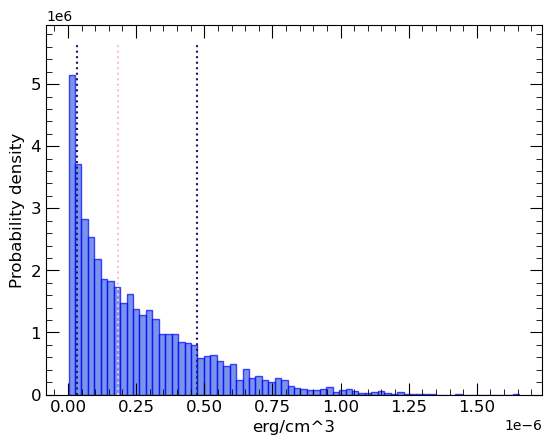

Median = 1.8270912178651635e-07 ; Lower limit =  3.41814829917765e-08 ; Upper limit =  4.735802157963216e-07


In [68]:
pC_new = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neC_new1[i], QC_new[i], disNrand[i], Rax[i], C1_rand[i]) for i in range(niter))

median = np.nanpercentile(pC_new,50)
low_lim = np.nanpercentile(pC_new,perc_low)
high_lim = np.nanpercentile(pC_new,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pC_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/cm^3', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pCmed_new = median
pClow_new = low_lim
pCup_new = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


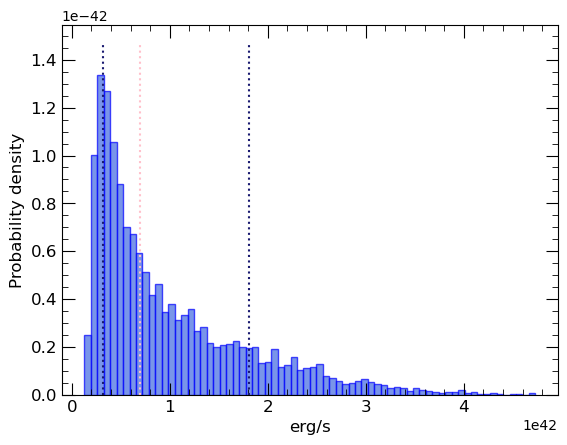

Median = 7.006690270559049e+41 ; Lower limit =  3.1753051165726826e+41 ; Upper limit =  1.803699110603573e+42


In [69]:
QC_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neC_new3[i], disNrand[i], v3_ccm[i], C1_rand[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QC_new3,50)
low_lim = np.nanpercentile(QC_new3,perc_low)
high_lim = np.nanpercentile(QC_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QC_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QCmed_new3 = median
QClow_new3 = low_lim
QCup_new3 = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


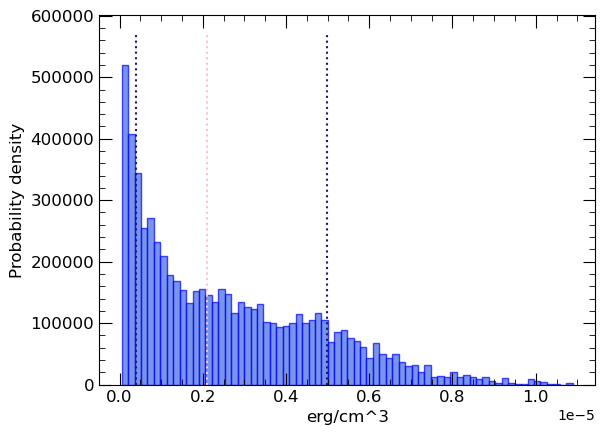

Median = 2.1041287894259123e-06 ; Lower limit =  4.001738998714137e-07 ; Upper limit =  4.995540007770958e-06


In [70]:
pC_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neC_new3[i], QC_new3[i], disNrand[i], Rax[i], C1_rand[i]) for i in range(niter))

median = np.nanpercentile(pC_new3,50)
low_lim = np.nanpercentile(pC_new3,perc_low)
high_lim = np.nanpercentile(pC_new3,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pC_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/cm^3', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pCmed_new3 = median
pClow_new3 = low_lim
pCup_new3 = high_lim

### Calorimetry in the case of the newest velocity estimate

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


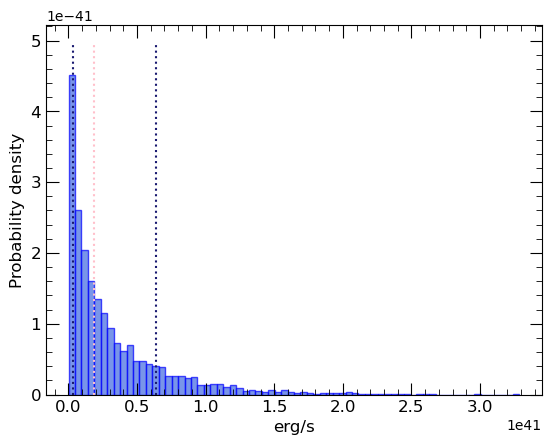

Median = 1.8474790859288507e+40 ; Lower limit =  3.4638432682445086e+39 ; Upper limit =  6.351841128451027e+40


In [71]:
QC_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neC_newvel[i], disNrand[i], vel[i], C1[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QC_newvel,50)
low_lim = np.nanpercentile(QC_newvel,perc_low)
high_lim = np.nanpercentile(QC_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QC_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QCmed_newvel = median
QClow_newvel = low_lim
QCup_newvel = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


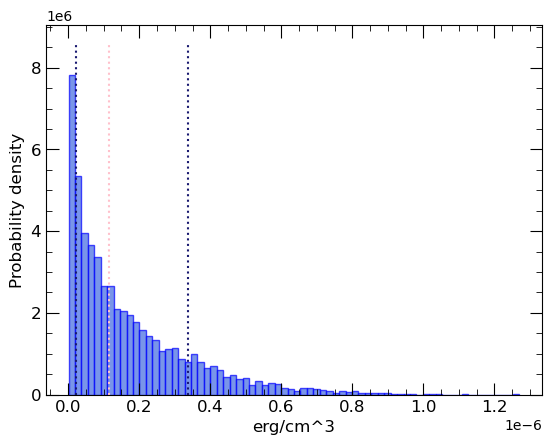

Median = 1.1522232321571726e-07 ; Lower limit =  2.1923034677606454e-08 ; Upper limit =  3.359555617659431e-07


In [72]:
pC_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neC_newvel[i], QC_newvel[i], disNrand[i], Rax[i], C1[i]) for i in range(niter))

median = np.nanpercentile(pC_newvel,50)
low_lim = np.nanpercentile(pC_newvel,perc_low)
high_lim = np.nanpercentile(pC_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pC_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/cm^3', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pCmed_newvel = median
pClow_newvel = low_lim
pCup_newvel = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


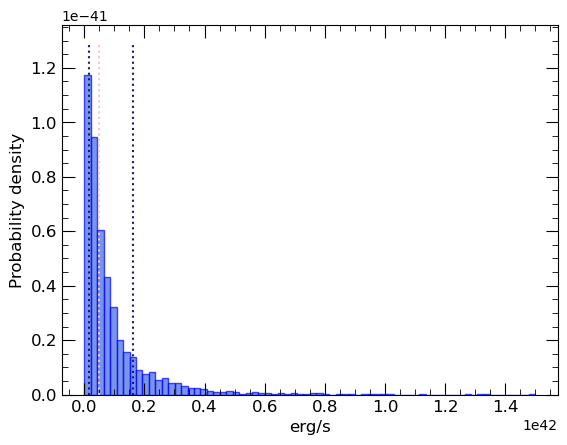

Median = 5.062663794228334e+40 ; Lower limit =  1.4640629071792046e+40 ; Upper limit =  1.6321361408236347e+41


In [73]:
QD_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neD_newvel[i], disSrand[i], vel[i], C1_rand[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QD_newvel,50)
low_lim = np.nanpercentile(QD_newvel,perc_low)
high_lim = np.nanpercentile(QD_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QD_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QDmed_newvel = median
QDlow_newvel = low_lim
QDup_newvel = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


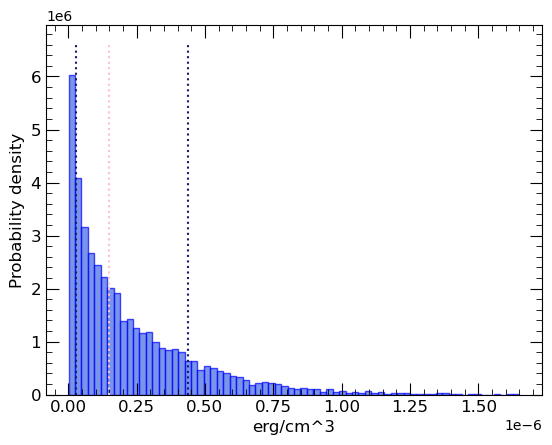

Median = 1.5041256114394637e-07 ; Lower limit =  2.823109731396493e-08 ; Upper limit =  4.389736528165907e-07


In [74]:
pD_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neD_newvel[i], QD_newvel[i], disSrand[i], Rax[i], C1_rand[i]) for i in range(niter))

median = np.nanpercentile(pD_newvel,50)
low_lim = np.nanpercentile(pD_newvel,perc_low)
high_lim = np.nanpercentile(pD_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pD_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/cm^3', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pDmed_newvel = median
pDlow_newvel = low_lim
pDup_newvel = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


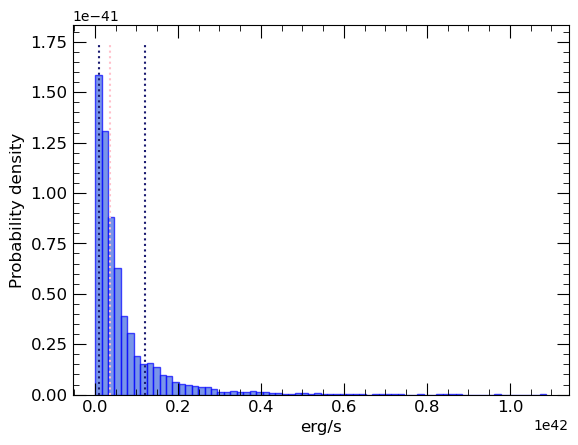

Median = 3.6517843507772774e+40 ; Lower limit =  1.0517507340252015e+40 ; Upper limit =  1.2080318672967653e+41


In [75]:
QE_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(power)(neE_newvel[i], disSrand[i], vel[i], C1_rand[i], incl_rand[i]) for i in range(niter))

median = np.nanpercentile(QE_newvel,50)
low_lim = np.nanpercentile(QE_newvel,perc_low)
high_lim = np.nanpercentile(QE_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(QE_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/s', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
QEmed_newvel = median
QElow_newvel = low_lim
QEup_newvel = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


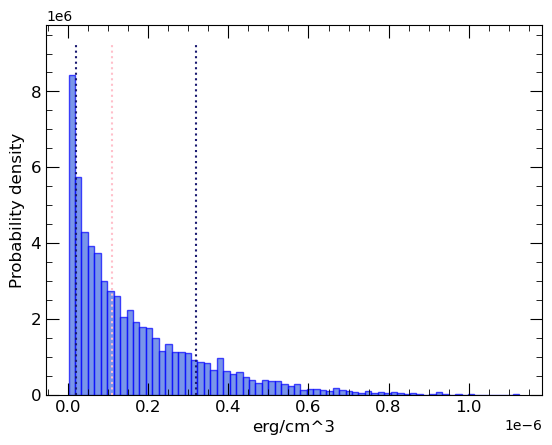

Median = 1.0870831092910351e-07 ; Lower limit =  2.06688077068078e-08 ; Upper limit =  3.188913207290468e-07


In [76]:
pE_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(pressure)(neE_newvel[i], QE_newvel[i], disSrand[i], Rax[i], C1_rand[i]) for i in range(niter))

median = np.nanpercentile(pE_newvel,50)
low_lim = np.nanpercentile(pE_newvel,perc_low)
high_lim = np.nanpercentile(pE_newvel,perc_up)

### PLOT
%matplotlib inline
histplot = plt.hist(pE_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel('erg/cm^3', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
pEmed_newvel = median
pElow_newvel = low_lim
pEup_newvel = high_lim

### Density estimate basing on northern jet age and power transferred 

The estimate of the electron density basing on synchrotron emission for regions A and B in the northern jet reveals a really low value. Here I will estimate the density using the information about the northern jet age (assuming the same velocity of the southern jet) and the power transferred (assuming the same for the southern jet). This is because for the southern jetwe are assuming bremmhstralung emission (basing on the spectral index we obtained) and the calculations were made in a reliable way. If we invert the relation:

$$ L_j = C_1 \left(\dfrac{Q_0}{\rho_0}\right)^{1/5}t^{3/5} $$

we will obtain:

$$\rho_0 = \dfrac{C_1^5Q_0t^3}{L_j^5} $$

where we are assuming $Q_0 = Q_{jet}$

In [77]:
distarcA = 1.096204*60 # arcsec
dispcApro = distarcA*0.048*d10   # parsec
dispcA = dispcApro/np.sin(incl*np.pi/180)
edisarcA = bmaj
edispcApro = edisarcA*0.048*d10
edispcA = edispcApro/np.sin(incl*np.pi/180)

distarcB = 49.716820 # arcsec
dispcBpro = distarcB*0.048*d10   # parsec
dispcB = dispcBpro/np.sin(incl*np.pi/180)
edisarcB = bmaj
edispcBpro = edisarcB*0.048*d10
edispcB = edispcBpro/np.sin(incl*np.pi/180)

def ne_from_t(C,Q,t,L):
    rh0 = (C**5)*((t*(365*24*60*60)*1e3)**3)*Q/((L*pc)**5)
    rh = 4*rh0
    n = rh/(1.370*mh)
    return n

def ne_from_v(C,Q,v,L):
    rh0 = (((3/5)**3)*(C**5)*Q)/(((L*pc)**2)*(v**3))
    rh = 4*rh0
    n = rh/(1.370*mh)
    return n

neNmax = ne_from_t(Con1_n, QmaxD, tmaxN, dispcN)
neNmin = ne_from_t(Con1_n, QminE, tminN, dispcN)

neNminC = ne_from_t(Con1_n, QminC, tminN, dispcN)
neNmaxC = ne_from_t(Con1_n, QmaxC, tmaxN, dispcN)

print('Mininimum electron density a posteriori for north lobe: [1/cm3]:', neNmin)
print('Maximum electron density a posteriori for north lobe: [1/cm3]:', neNmax)
print('\n')
print('Mininimum electron density a posteriori for north lobe (using region C min power): [1/cm3]:', neNminC)
print('Maximum electron density a posteriori for north lobe (using region C max power): [1/cm3]:', neNmaxC)

Mininimum electron density a posteriori for north lobe: [1/cm3]: 0.005519001673323769
Maximum electron density a posteriori for north lobe: [1/cm3]: 1058325.3078015025


Mininimum electron density a posteriori for north lobe (using region C min power): [1/cm3]: 0.00649204829562298
Maximum electron density a posteriori for north lobe (using region C max power): [1/cm3]: 575935.7461450357


In [78]:
print(dispcA, edispcA)

3.0681990928113243 0.29537349535027824


In [79]:
30*0.048*d10

1.224

Ok maybe here it's the case to use a CCM chain

### CM-based $n_e$ estimate ($n_e$ for A and B region, assuming same properties of bremhstralung regions)

In [80]:
niter = niter
ncores = 1
np.random.seed(124)

# Source parameters (Q and t)
#Qmean = np.mean([QminC, QmaxC, QminD, QmaxD, QminE, QmaxE])
#Qstd = np.std([QminC, QmaxC, QminD, QmaxD, QminE, QmaxE])
#Qmean = np.mean([QminC, QminD, QminE])
#Qstd = np.std([QminC,QminD, QminE])
Qmean = np.percentile([QCmed, QDmed, QEmed], 50)
Qstd = np.std([QCmed, QDmed, QEmed])
#Qlow_lim = np.percentile([QClow, QDlow, QElow, QCup, QDup, QEup], 5)
#Qhigh_lim = np.percentile([QClow, QDlow, QElow, QCup, QDup, QEup], 95)
tmean = np.mean([tminN, tmaxN])
tstd = np.std([tminN, tmaxN])
#Qrand = np.random.normal(Qmean, Qstd, niter)
#trand = np.random.normal(tmean, tstd, niter)
#disArand = np.random.normal(dispcA, edispcA, niter)
#disBrand = np.random.normal(dispcB, edispcB, niter)
Qmin = min(QClow, QDlow, QElow)
Qmax = max(QCup, QDup, QEup)
#Qrand = np.random.uniform(Qmin, Qmax, niter)
Qrand = np.random.uniform(Qmean-Qstd, Qmean+Qstd, niter)
trand = np.random.uniform(tminN, tmaxN, niter)
disArand = np.random.uniform(dispcA-edispcA, dispcA+edispcA, niter)
disBrand = np.random.uniform(dispcB-edispcB, dispcB+edispcB, niter)
print(Qmean, Qstd)

2.7369913660330418e+35 1.2270169982698221e+35


In [81]:
#ne_cm = Parallel(n_jobs=ncores, verbose=5)(delayed(ne_from_t)(Con1_n, Qrand[i], tN[i], disArand[i]) for i in range(niter))
ne_cm = Parallel(n_jobs=ncores, verbose=5)(delayed(ne_from_t)(Con1_n, QC[i], tN[i], disArand[i]) for i in range(niter))

median = np.percentile(ne_cm,50)
low_lim = np.percentile(ne_cm,perc_low)
high_lim = np.percentile(ne_cm,perc_up)
neAt_med = median
neAtlow = low_lim
neAtup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


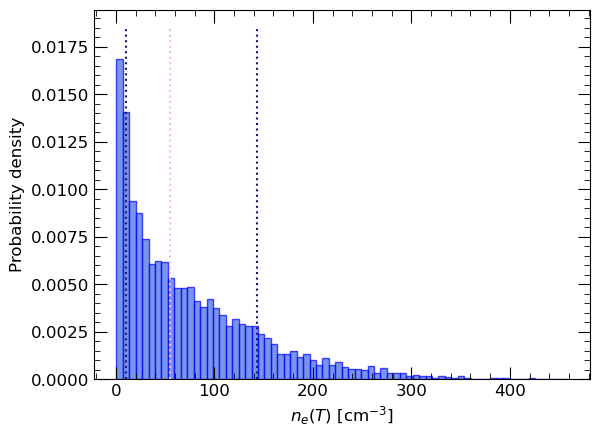

Median = 54.946162261165895 ; Lower limit =  10.392371660835233 ; Upper limit =  143.56544299968922


In [82]:
### PLOT
%matplotlib inline
histplot = plt.hist(ne_cm,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


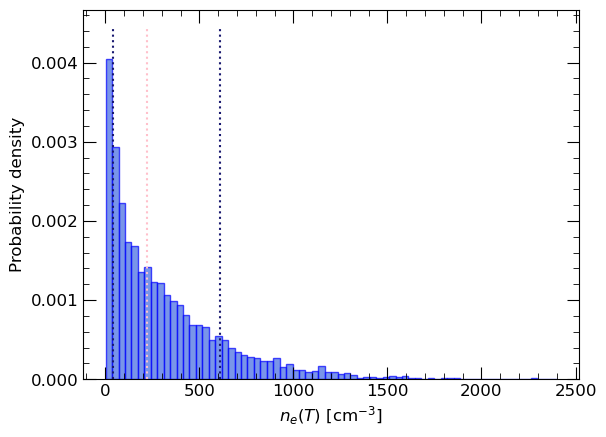

Median = 224.04317532761445 ; Lower limit =  41.69803781692907 ; Upper limit =  609.7878220449951


In [83]:
ne_cm = Parallel(n_jobs=ncores, verbose=5)(delayed(ne_from_t)(Con1_n, QC[i], tN[i], disBrand[i]) for i in range(niter))

median = np.percentile(ne_cm,50)
low_lim = np.percentile(ne_cm,perc_low)
high_lim = np.percentile(ne_cm,perc_up)
neBt_med = median
neBtlow = low_lim
neBtup = high_lim

### PLOT
%matplotlib inline
histplot = plt.hist(ne_cm,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

Probably it will be the exact same thing, but I'll try with:

$$Q_{jet} = Q_0 = \left(\dfrac{5}{3}\right)^3 \dfrac{\rho_0}{C_1^5}L_j^2\dot{L_j^3}$$

obtaining:

$$\rho_0 = \left(\dfrac{3}{5}\right)^3\dfrac{C_1^5Q_0}{L_j^2\dot{L_j^3}} $$

In [84]:
#vmean = np.mean([vmin,vmax])
#vstd = np.std([vmin,vmax])
#Qmeanv = np.mean([QminC, QmaxC])
#Qstdv = np.std([QminC, QmaxC])
#vrand = np.random.normal(vmean, vstd, niter)
#Qrandv = np.random.normal(Qmeanv, Qstdv, niter)

#nev_cm = Parallel(n_jobs=ncores, verbose=5)(delayed(ne_from_v)(Con1_n, Qrand[i], vrand[i], disArand[i]) for i in range(niter))
nev_cm = Parallel(n_jobs=ncores, verbose=5)(delayed(ne_from_v)(Con1_n, QC[i], vrand[i], disArand[i]) for i in range(niter))

median = np.percentile(nev_cm,50)
low_lim = np.percentile(nev_cm,perc_low)
high_lim = np.percentile(nev_cm,perc_up)
neAv_med = median
neAvlow = low_lim
neAvup = high_lim

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


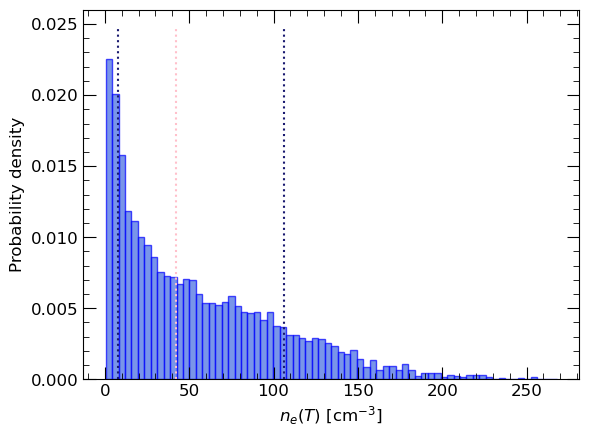

Median = 42.25300887880907 ; Lower limit =  7.994822075719312 ; Upper limit =  106.13644084571457


In [85]:
### PLOT
%matplotlib inline
histplot = plt.hist(nev_cm,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(-1e14,1e14)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

In [86]:
print(neAv_med, neAt_med)

42.25300887880907 54.946162261165895


In [87]:
print(neAvlow, neAtlow)

7.994822075719312 10.392371660835233


### Where is the southern jet now?

If we assume that the northern jet is arrived in the region of impact in a time $t_n$ and the souther jet launched at the same time is not yet arrived on the other part (as we have computer, the jet we are observing is older), than using $t_n$ and $L_n$ we can compute the velocity $v_n$ and, assuming $v_s = v_n$ than we can also measure the distance reached by the jet in the south launched at the same time with the northern one. 
Obviously the velocity is the one we assumed using the bremstralung model emission. So the distance in parsec is the one measured for the north lobe: the point is to convert in arcsec considering the effect of the inclination angle i. Ok but so in this way I have the same distance in arcsec of the north lobe??

In [88]:
def lenght(v,t):
    le = v*(t*(365*24*60*60)*1e3)
    lepc = le/pc
    return lepc

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


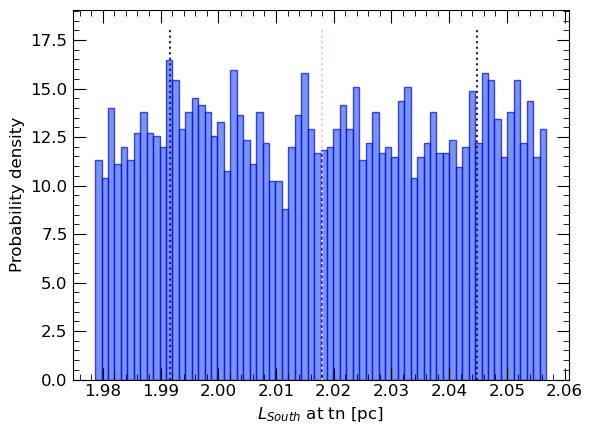

Median = 2.0179810014593165 ; Lower limit =  1.9915766310227205 ; Upper limit =  2.0448782775480465


In [89]:
lstn = Parallel(n_jobs=ncores, verbose=5)(delayed(lenght)(vrand[i], tN[i]) for i in range(niter))

median = np.percentile(lstn,50)
low_lim = np.percentile(lstn,perc_low)
high_lim = np.percentile(lstn,perc_up)
neBt_med = median
neBtlow = low_lim
neBtup = high_lim

### PLOT
%matplotlib inline
histplot = plt.hist(lstn,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_{South}$ at tn [pc]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

## Synchrotron emission (A and B regions, equipartition)

Now the total number of electrons is defined by:

$$ N = \dfrac{N_0}{1-p}(E_2^{1-p}-E_1^{1-p})$$

while the electons total energy is:

$$ E_e = \dfrac{N_0}{2-p}(E_2^{2-p}-E_1^{2-p})$$

and the observed (integrated) luminosity is:

$$ L = \dfrac{N_0c_2B^2}{3-p}(E_2^{3-p}-E_1^{3-p})$$

also:

$$ E = \dfrac{\nu^{1/2}}{c_1^{1/2}B^{1/2}}$$

the convention we are using for the spectral index is:

$$\alpha = \dfrac{1-p}{2}$$ 

We can determine the constant $N_0$ for example in this way (using L):

$$ N_0 = \dfrac{(3-p)}{c_2B^2}\dfrac{L}{(E_2^{3-p}-E_1^{3-p})}$$

and then using the frequencies instead of the energies and after some passages:

$$ N = \dfrac{(3-p)}{(1-p)}\dfrac{c_1L}{c_2B}\dfrac{[\nu_2^{(1-p)/2}-\nu_1^{(1-p)/2}]}{[\nu_2^{(3-p)/2}-\nu_1^{(3-p)/2}]}$$

The magnetic field B at equipartition is: 

$$ B = \left(6\pi\dfrac{\eta}{f}c_{12}\dfrac{L}{V}\right)^{2/7}$$

where f = filling factor, $\eta = 1$ usually and indicates how much energy is in the protons linked to the electrons and

$$ c_{12} = \dfrac{c_1^{1/2}}{c_2}\dfrac{(3-p)}{(2-p)}\dfrac{[\nu_2^{(2-p)/2}-\nu_1^{(2-p)/2}]}{[\nu_2^{(3-p)/2}-\nu_1^{(3-p)/2}]}$$

to compute the integrated luminosity having the measure of the flux at a certain value of $\nu = \nu_2$:

$$ L = 8\pi d^2F_{\nu_2}\nu_2^{(p-1)/2}\left[\dfrac{\nu_2^{(2-p)/2}-\nu_1^{(2-p)/2}}{2-p}\right]$$

so, with all of that, it's possible to estimate the number density of electrons in the regions A and B emitting synchrotron emission. In fact we have measured their luminosity, also we have computed the spectral index; for region A we can calculate its volume assuming a spherical region with a dimension comparabable to the beam dimension (in fact this region is only slightly resolved). For region B, that has a more complex structure, things are a bit more complicated: at order zero we can approximate the region with a cylinder and see what happens. If this model brutally fails, we will consider to update it.

In [90]:
# Pseudoconstant
c1=6.27e18
c2=2.37e-3

# Spectral info
#alphaA = -0.5768532641828952
#ealphaA = 0.34833186481062606
alphaA = -0.7662418503253722
ealphaA = 0.28906092463099986
pA = 1-(2*alphaA)
epA = 2*ealphaA
#pA = 2.5
#alphaA = (1-pA)/2
#nu1, nu2 = 0.963e9, 1.605e9  # range of frequencies in Hz used to compute the spectral index (actually all 4 channels)
#nu1, nu2 = 1e7, 1e11
#ener1= me*c*c
#ener2 = (10**6)*ener1
nu1, nu2 = 1e7, 1e11
eta, f = 1, 0.1
# Flux density in mJy (taken from the averaged image)
FA, eFA = 0.3057604387766753, 0.03057604387766753  # in mJy
#FA = 0.3
rAcm = bmaj*(0.048*d10*pc) #np.sin(incl*np.pi/180)
#rAcm = 6*(0.048*d10*pc)
VolA = (4/3)*np.pi*(rAcm**3)
#VolA = np.pi*(rAcm**2)
dkpc = d10*10

In [91]:
def nu_from_E(E,B):
    return c1*B*E*E

In [92]:
def const12(p, c1, c2, nu1, nu2):
    top = (c1**(1/2))*(3-p)*(nu2**((2-p)/2)-nu1**((2-p)/2))
    bottom = c2*(2-p)*(nu2**((3-p)/2)-nu1**((3-p)/2))
    return top/bottom

def Beq(L, V, c12, eta, f):
    return (6*np.pi*(eta/f)*c12*(L/V))**(2/7)

def Beq2(eta, c12, L, f, r):
    return ((4.5 * eta * c12 * L)**(2.0/7.0))*(f**(-2.0/7.0))*(r**(-6.0/7.0))

#From the Thunderbooks, written as it is, requires dist in kpc and Fnu=Fmean here in mJy
def Ltot(alpha, dist, Fmean, nu1, nu2):
    Fnu2 = Fmean*((nu2/1.284e9)**alpha)
    #Fnu2 = Fmean
    L = 4*np.pi*((dist*3.1e21)**2)*(Fnu2*1e-26)*(nu2**(-alpha))*((nu2**(1+alpha))-(nu1**(1+alpha)))/(1+alpha)
    return L

def Ntot(p, c1, c2, nu1, nu2, L, B):
    top = (3-p)*c1*L*(nu2**((1-p)/2)-nu1**((1-p)/2))
    bottom = (1-p)*c2*B*(nu2**((3-p)/2)-nu1**((3-p)/2))
    return top/bottom

def Emin(eta, c12, B, L):
    return (7/4)*eta*c12*(B**(-3/2))*L

def pEmin(B, k=0.01):
    p = (7/9)*(B**2)*(k+1)/(8*np.pi)
    return p

Here I try to also give an estimate of volume of region B. It's quite hard to individuate a geometric form in this region, so I'm trying to convince myself that a cone modelled with the same dimension of the beam and an higness rudely defined using distance calculator in CARTA is fine

In [93]:
hBarc = np.mean([22,27]) #Higness in arcsecond measured in different points between the structure of region B is between the range chosen
hBarc_std = np.std([22,27])
#alphaB = -0.5294036790245514
#ealphaB = 0.2984490125266435
alphaB = -0.6671515869346824
ealphaB = 0.23187379140012296
pB = 1-(2*alphaB)
epB = 2*ealphaB
FB, eFB = 0.33272653150162423, 0.03327265315016242
hBcm = hBarc*(0.048*d10*pc)/np.sin(incl*np.pi/180)
Abeam = np.pi*((bmaj/2)*(0.048*d10*pc))**2
VolB = hBcm*Abeam
#hABcm = 34*(0.048*d10*pc)/np.sin(incl*np.pi/180)
#VolAB = hABcm*Abeam
#hABCcm = 40*(0.048*d10*pc)/np.sin(incl*np.pi/180)
#AreaABC = np.pi*(24/2)**2*(0.048*d10*pc)**2
#VolABC = AreaABC*hABCcm

ax1 = 15*(0.048*d10*pc)
ax2 = 6*(0.048*d10*pc)
Vo1 = (4/3)*np.pi*ax1*ax1*ax2
Vo2 = (4/3)*np.pi*ax1*ax2*ax2

c12_B = const12(pB, c1, c2, nu1, nu2)
LintB = Ltot(alphaB, dkpc, FB, nu1, nu2)
BB = Beq(LintB, VolB, c12_B, eta, f)
#BB2 = Beq2(eta, c12, LintB, f, rAcm)
NB = Ntot(pB, c1, c2, nu1, nu2, LintB, BB)
nB = NB/(VolB*f)
EminB = Emin(eta,c12_B,BB,LintB)
pEminB = pEmin(BB)

print('Values with nominal value of spectral index of region B')
print('Equipartition magnetic field [G]:', BB)
#print('Equipartition magnetic field (sphere) [G]:', BB2)
print('Integrated luminosity of region B [erg/s]:', LintB)
print('Volume of region B [cm3]', VolB)
print('Electron density in regionB considering synchrotron emission at equipartition [1/cm3]', nB)
print('Variable c12:', '%.2e' %c12_B)
print('Minimum energy region B [erg]', EminB)
print('Pressure at minimum energy in region B [erg/cm3]:', pEminB)

Values with nominal value of spectral index of region B
Equipartition magnetic field [G]: 5.514081960474522e-05
Integrated luminosity of region B [erg/s]: 4.5499075233706315e+29
Volume of region B [cm3] 1.76062229626466e+54
Electron density in regionB considering synchrotron emission at equipartition [1/cm3] 3.018657252016864e-07
Variable c12: 2.56e+07
Minimum energy region B [erg] 4.969921821761383e+43
Pressure at minimum energy in region B [erg/cm3]: 9.503497807997859e-11


In [94]:
hBarc*(0.048*d10)/np.sin(incl*np.pi/180)

1.142896726246171

In [95]:
def const12(p, c1, c2, nu1, nu2):
    top = (c1**(1/2))*(3-p)*(nu2**((2-p)/2)-nu1**((2-p)/2))
    bottom = c2*(2-p)*(nu2**((3-p)/2)-nu1**((3-p)/2))
    return top/bottom

def Beq(L, V, c12, eta, f):
    return (6*np.pi*(eta/f)*c12*(L/V))**(2/7)

def Beq2(eta, c12, L, f, r):
    return ((4.5 * eta * c12 * L)**(2.0/7.0))*(f**(-2.0/7.0))*(r**(-6.0/7.0))

#From the Thunderbooks, written as it is, requires dist in kpc and Fnu=Fmean here in mJy
def Ltot(alpha, dist, Fmean, nu1, nu2):
    Fnu2 = Fmean*((nu2/1.284e9)**alpha)
    #Fnu2 = Fmean
    L = 4*np.pi*((dist*3.1e21)**2)*(Fnu2*1e-26)*(nu2**(-alpha))*(nu2**(1+alpha)-nu1**(1+alpha))/(1+alpha)
    return L

def Ntot(p, c1, c2, nu1, nu2, L, B):
    top = (3-p)*c1*L*((nu2**((1-p)/2))-(nu1**((1-p)/2)))
    bottom = (1-p)*c2*B*((nu2**((3-p)/2))-(nu1**((3-p)/2)))
    return top/bottom

def Ntot2(p, c1, c2, nu1, nu2, L, B):
    c12 = const12(p, c1, c2, nu1, nu2)
    top = (2-p)*c12*(c1**(1/2))*L*(nu2**((1-p)/2)-nu1**((1-p)/2))
    bottom = (1-p)*B*(nu2**((2-p)/2)-nu1**((2-p)/2))
    return top/bottom

In [96]:
c12 = const12(pA, c1, c2, nu1, nu2)
LintA = Ltot(alphaA, dkpc, FA, nu1, nu2)
BA = Beq(LintA, VolA, c12, eta, f)
#nu1 = nu_from_E(ener1,BA)
#nu2 = nu_from_E(ener2,BA)
BA2 = Beq2(eta, c12, LintA, f, rAcm)
NA = Ntot(pA, c1, c2, nu1, nu2, LintA, BA)
nA = NA/(VolA*f)
EminA = Emin(eta,c12,BA,LintA)
pEminA = pEmin(BA)

print('Values with nominal value of spectral index of region A')
print('Equipartition magnetic field [G]:', BA)
print('Equipartition magnetic field (sphere) [G]:', BA2)
print('Integrated luminosity of region A [erg/s]:', LintA)
print('Volume of region A [cm3]', VolA)
print('Total number of electrons in region A:', NA)
print('Electron density in region A considering synchrotron emission at equipartition [1/cm3]', nA)
print('Variable c12:', '%.2e' %c12)
print('Minimum energy region A [erg]', EminA)
print('Pressure at minimum energy in region A [erg/cm3]:', pEminA)


c12_plus = const12(pA-epA, c1, c2, nu1, nu2)
LintA_plus = Ltot(alphaA+ealphaA, dkpc, FA, nu1, nu2)
BA_plus = Beq(LintA_plus, VolA, c12_plus, eta, f)
#BA2 = Beq2(eta, c12, LintA, f, rAcm)
NA_plus = Ntot(pA-epA, c1, c2, nu1, nu2, LintA_plus, BA_plus)
nA_plus = NA_plus/(VolA*f)

print('\n')
print('Values with maximum value of spectral index of region A')
print('Equipartition magnetic field [G]:', BA_plus)
#print('Equipartition magnetic field (sphere) [G]:', BA2)
print('Integrated luminosity of region A [erg/s]:', LintA_plus)
print('Volume of region A [cm3]', VolA)
print('Electron density in region A considering synchrotron emission at equipartition [1/cm3]', nA_plus)
print('Variable c12:', '%.2e' %c12_plus)

c12_minus = const12(pA+epA, c1, c2, nu1, nu2)
LintA_minus = Ltot(alphaA-ealphaA, dkpc, FA, nu1, nu2)
BA_minus = Beq(LintA_minus, VolA, c12_minus, eta, f)
#BA2 = Beq2(eta, c12, LintA, f, rAcm)
NA_minus = Ntot(pA+epA, c1, c2, nu1, nu2, LintA_minus, BA_minus)
nA_minus = NA_minus/(VolA*f)

print('\n')
print('Values with minimum value of spectral index of region A')
print('Equipartition magnetic field [G]:', BA_minus)
#print('Equipartition magnetic field (sphere) [G]:', BA2)
print('Integrated luminosity of region A [erg/s]:', LintA_minus)
print('Volume of region A [cm3]', VolA)
print('Electron density in region A considering synchrotron emission at equipartition [1/cm3]', nA_minus)
print('Variable c12:', '%.2e' %c12_minus)

Values with nominal value of spectral index of region A
Equipartition magnetic field [G]: 5.351909175561695e-05
Equipartition magnetic field (sphere) [G]: 5.351909175561696e-05
Integrated luminosity of region A [erg/s]: 3.584877945940635e+29
Volume of region A [cm3] 2.122504979021524e+54
Total number of electrons in region A: 7.097307779786051e+46
Electron density in region A considering synchrotron emission at equipartition [1/cm3] 3.343835632865235e-07
Variable c12: 3.52e+07
Minimum energy region A [erg] 5.644209333563388e+43
Pressure at minimum energy in region A [erg/cm3]: 8.952709939816861e-11


Values with maximum value of spectral index of region A
Equipartition magnetic field [G]: 4.898980829535344e-05
Integrated luminosity of region A [erg/s]: 6.3344690709802534e+29
Volume of region A [cm3] 2.122504979021524e+54
Electron density in region A considering synchrotron emission at equipartition [1/cm3] 1.424980819144926e-07
Variable c12: 1.46e+07


Values with minimum value of spec

### CM-based $L_{int}$ estimate
#### Region A

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


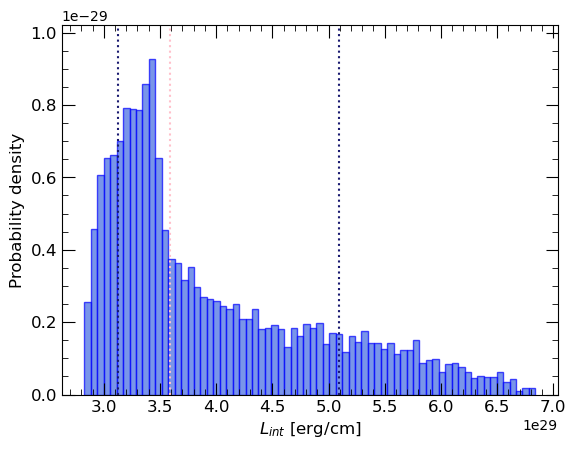

Median = 3.5912254300737314e+29 ; Lower limit =  3.1277845106260553e+29 ; Upper limit =  5.09356782016802e+29
4.634409194476761e+28 -1.5023423900942887e+29


In [97]:
alphaA_rand = np.random.uniform(alphaA-ealphaA, alphaA+ealphaA, niter)
pA_rand = np.random.uniform(pA-epA, pA+epA, niter)
FA_rand = np.random.uniform(FA-eFA, FA+eFA, niter)

LA_sync = Parallel(n_jobs=ncores, verbose=5)(delayed(Ltot)(alphaA_rand[i], dkpc, FA_rand[i], nu1, nu2) for i in range(niter))

median = np.percentile(LA_sync,50)
low_lim = np.percentile(LA_sync,perc_low)
high_lim = np.percentile(LA_sync,perc_up)
LAs_med = median
LAslow = low_lim
LAsup = high_lim
### PLOT
%matplotlib inline
histplot = plt.hist(LA_sync,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_{int}$ [erg/cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print(median-low_lim, median-high_lim)

#### Region B

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


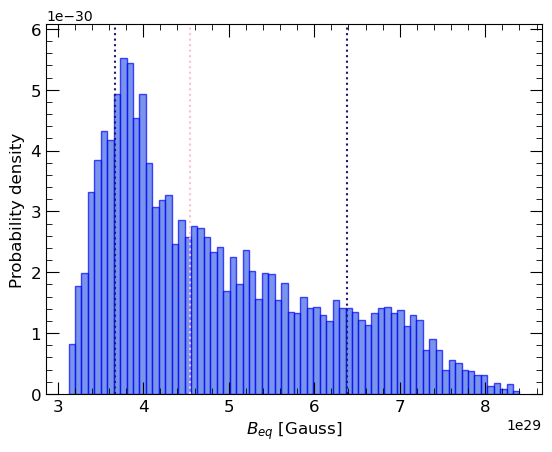

Median = 4.544849328013136e+29 ; Lower limit =  3.667240340326258e+29 ; Upper limit =  6.379039585079332e+29
8.776089876868782e+28 -1.8341902570661962e+29


In [98]:
alphaB_rand = np.random.uniform(alphaB-ealphaB, alphaB+ealphaB, niter)
pB_rand = np.random.uniform(pB-epB, pB+epB, niter)
FB_rand = np.random.uniform(FB-eFB, FB+eFB, niter)

LB_sync = Parallel(n_jobs=ncores, verbose=5)(delayed(Ltot)(alphaB_rand[i], dkpc, FB_rand[i], nu1, nu2) for i in range(niter))

median = np.percentile(LB_sync,50)
low_lim = np.percentile(LB_sync,perc_low)
high_lim = np.percentile(LB_sync,perc_up)
LAs_med = median
LAslow = low_lim
LAsup = high_lim
### PLOT
%matplotlib inline
histplot = plt.hist(LB_sync,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$B_{eq}$ [Gauss]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print(median-low_lim, median-high_lim)

### CM-based $B_{eq}$ estimate

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


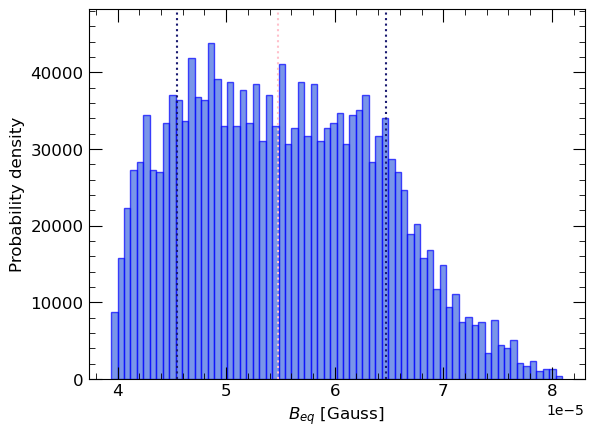

Median = 5.477536512761161e-05 ; Lower limit =  4.5467848045185775e-05 ; Upper limit =  6.476715600293022e-05


In [99]:
alphaA_rand = np.random.uniform(alphaA-ealphaA, alphaA+ealphaA, niter)
pA_rand = np.random.uniform(pA-epA, pA+epA, niter)
FA_rand = np.random.uniform(FA-eFA, FA+eFA, niter)

def B_from_syn(p, alpha, c1, c2, nu1, nu2, dkpc, F, Vol):
    c12 = const12(p, c1, c2, nu1, nu2)
    Lint = Ltot(alpha, dkpc, F, nu1, nu2)
    B = Beq(Lint, Vol, c12, eta, f)
    return B

B_sync = Parallel(n_jobs=ncores, verbose=5)(delayed(B_from_syn)(pA_rand[i], alphaA_rand[i], c1, c2, nu1, nu2, dkpc, FA_rand[i], VolA) for i in range(niter))

median = np.percentile(B_sync,50)
low_lim = np.percentile(B_sync,perc_low)
high_lim = np.percentile(B_sync,perc_up)
BAs_med = median
BAslow = low_lim
BAsup = high_lim
### PLOT
%matplotlib inline
histplot = plt.hist(B_sync,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$B_{eq}$ [Gauss]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


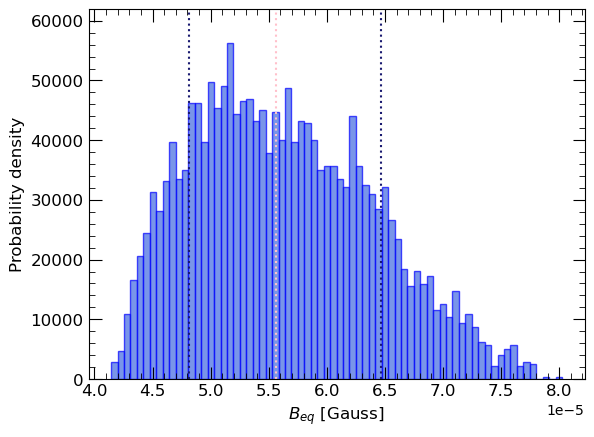

Median = 5.562945198553105e-05 ; Lower limit =  4.8172976454782664e-05 ; Upper limit =  6.462994524613932e-05


In [100]:
alphaB_rand = np.random.uniform(alphaB-ealphaB, alphaB+ealphaB, niter)
pB_rand = np.random.uniform(pB-epB, pB+epB, niter)
FB_rand = np.random.uniform(FB-eFB, FB+eFB, niter)

def B_from_syn(p, alpha, c1, c2, nu1, nu2, dkpc, F, Vol):
    c12 = const12(p, c1, c2, nu1, nu2)
    Lint = Ltot(alpha, dkpc, F, nu1, nu2)
    B = Beq(Lint, Vol, c12, eta, f)
    return B

BB_sync = Parallel(n_jobs=ncores, verbose=5)(delayed(B_from_syn)(pB_rand[i], alphaB_rand[i], c1, c2, nu1, nu2, dkpc, FB_rand[i], VolB) for i in range(niter))

median = np.percentile(BB_sync,50)
low_lim = np.percentile(BB_sync,perc_low)
high_lim = np.percentile(BB_sync,perc_up)
BBs_med = median
BBslow = low_lim
BBsup = high_lim
### PLOT
%matplotlib inline
histplot = plt.hist(BB_sync,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$B_{eq}$ [Gauss]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

### CM-based $p_{Emin}$ estimate

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


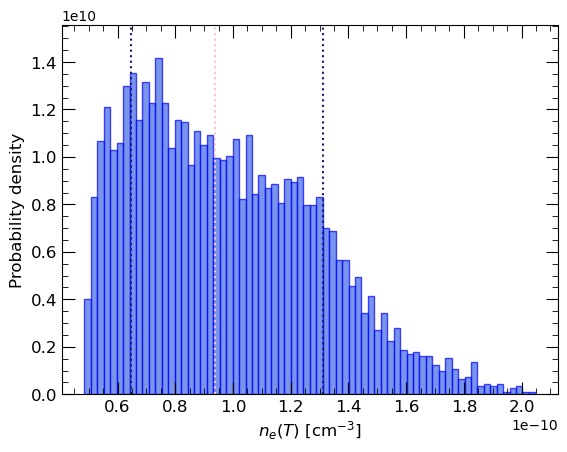

Median = 9.377943701847217e-11 ; Lower limit =  6.461685999492203e-11 ; Upper limit =  1.311132850950582e-10


In [101]:
pEminA = Parallel(n_jobs=ncores, verbose=5)(delayed(pEmin)(B_sync[i]) for i in range(niter))
median = np.percentile(pEminA,50)
low_lim = np.percentile(pEminA,perc_low)
high_lim = np.percentile(pEminA,perc_up)
pEminA_med = median
pEminAlow = low_lim
pEminAsup = high_lim
histplot = plt.hist(pEminA,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


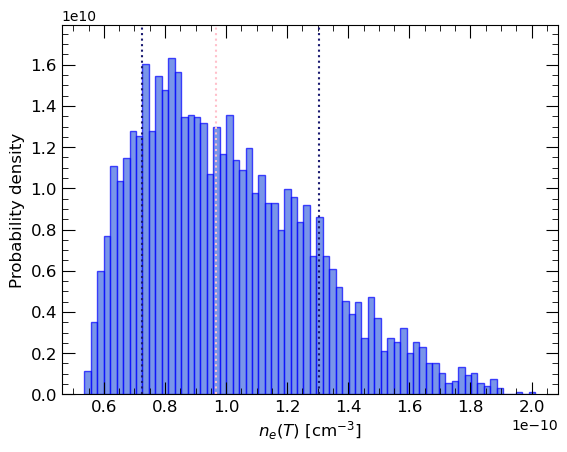

Median = 9.67267527148508e-11 ; Lower limit =  7.253439722945944e-11 ; Upper limit =  1.3055834033930621e-10


In [102]:
pEminB = Parallel(n_jobs=ncores, verbose=5)(delayed(pEmin)(BB_sync[i]) for i in range(niter))
median = np.percentile(pEminB,50)
low_lim = np.percentile(pEminB,perc_low)
high_lim = np.percentile(pEminB,perc_up)
pEminB_med = median
pEminBlow = low_lim
pEminBsup = high_lim
histplot = plt.hist(pEminB,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

### CM-based $n_e$ estimate ($n_e$ from synchrotron)

In [103]:
niter = niter
ncores = 1

def ne_from_syn(p, alpha, c1, c2, nu1, nu2, dkpc, F, Vol):
    c12 = const12(p, c1, c2, nu1, nu2)
    Lint = Ltot(alpha, dkpc, F, nu1, nu2)
    B = Beq(Lint, Vol, c12, eta, f)
    N = Ntot(p, c1, c2, nu1, nu2, Lint, B)
    n = N/(Vol*f)
    return n

def ne_from_syn2(p, alpha, c1, c2, nu1, nu2, dkpc, F, Vol):
    c12 = const12(p, c1, c2, nu1, nu2)
    Lint = Ltot(alpha, dkpc, F, nu1, nu2)
    B = Beq(Lint, Vol, c12, eta, f)
    N = Ntot2(p, c1, c2, nu1, nu2, Lint, B)
    n = N/(Vol*f)
    return n

def ne_VLA(p, alpha, c1, c2, nu1, nu2, dkpc, F, Vol):
    c12 = const12(p, c1, c2, nu1, nu2)
    Lint = Ltot(alpha, dkpc, F, nu1, nu2)
    #Lint = 7.1e30
    #Lint = 4*np.pi*((dkpc*3.1e21)**2)*(F*1e-26)
    #B = 4.7e-5
    B = Beq(Lint, Vol, c12, eta, f)
    B1 = Beq2(eta, c12, Lint, f, ax1/2)
    B2 = Beq2(eta, c12, Lint, f, ax2/2)
    #B = 4.7e-9
    N = Ntot(p, c1, c2, nu1, nu2, Lint, B)
    n = N/(Vol*f)
    print(B, B1, B2, Lint, Vol)
    return n

print(ne_VLA(2.5, -0.7, c1, c2, nu1, nu2, dkpc, 0.26, Vo1))
print(ne_VLA(2.5, -0.7, c1, c2, nu1, nu2, dkpc, 0.26, Vo2))

3.210300377441176e-05 4.475836721375333e-05 9.81670343560166e-05 3.359803894741671e+29 1.128731466187099e+55
9.076084822012006e-08
4.171025213938426e-05 4.475836721375333e-05 9.81670343560166e-05 3.359803894741671e+29 4.5149258647483957e+54
1.7463906974492457e-07


In [104]:
#alphaA_rand = np.random.normal(alphaA, ealphaA, niter)
#pA_rand = np.random.normal(pA, epA, niter)
#FA_rand = np.random.normal(FA, eFA, niter)

alphaA_rand = np.random.uniform(alphaA-ealphaA, alphaA+ealphaA, niter)
pA_rand = np.random.uniform(pA-epA, pA+epA, niter)
FA_rand = np.random.uniform(FA-eFA, FA+eFA, niter)

ne_sync = Parallel(n_jobs=ncores, verbose=5)(delayed(ne_from_syn)(pA_rand[i], alphaA_rand[i], c1, c2, nu1, nu2, dkpc, FA_rand[i], VolA) for i in range(niter))

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


~~Clearly something is off, as we have kinda a lot of order of difference comparing to the bremstralung derivation above. Maybe the problem is in the derivation I have used for N. Trying a different approach, so using also $E_e$, described both above and by:~~

$$ E_e = c_{12}\dfrac{L}{B^{3/2}}$$ 

we will obtain:

$$ N = \dfrac{(2-p)}{(1-p)}c_{12}c_1^{1/2}\dfrac{L}{B}\dfrac{[\nu_2^{(1-p)/2}-\nu_1^{(1-p)/2}]}{[\nu_2^{(2-p)/2}-\nu_1^{(2-p)/2}]}$$

RESOLVED: I was messing up with my own definitions of functions, now I have demonstrated that the two derivations are practically the same thing

In [105]:
median = np.percentile(ne_sync,50)
low_lim = np.percentile(ne_sync,perc_low)
high_lim = np.percentile(ne_sync,perc_up)
neAs_med = median
neAslow = low_lim
neAsup = high_lim

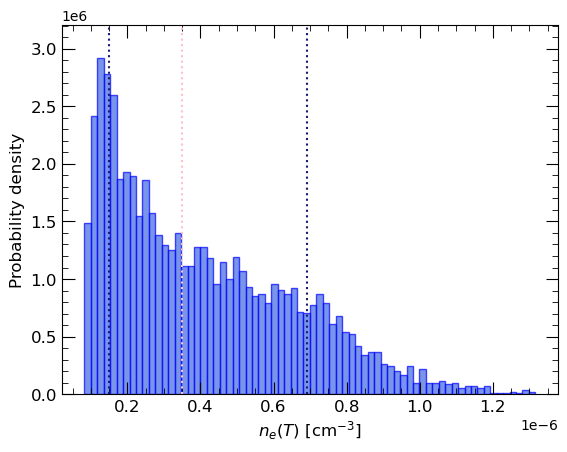

Median = 3.490434670248373e-07 ; Lower limit =  1.5076185643854863e-07 ; Upper limit =  6.902966755189277e-07
Unshocked values (min e max) [cm-3]: 3.7690464109637156e-08 1.7257416887973193e-07


In [106]:
### PLOT
%matplotlib inline
histplot = plt.hist(ne_sync,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Unshocked values (min e max) [cm-3]:', low_lim/4, high_lim/4)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


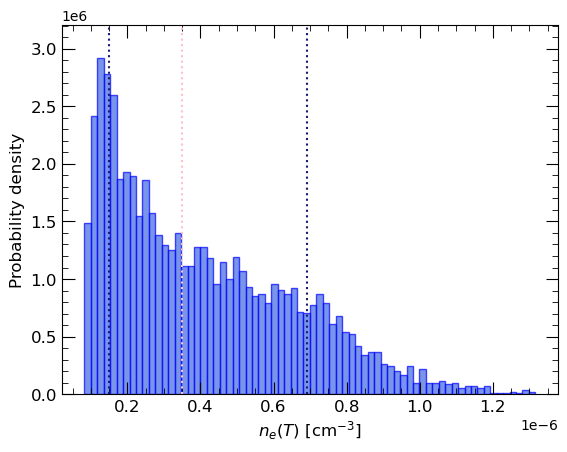

Median = 3.4904346702483727e-07 ; Lower limit =  1.507618564385486e-07 ; Upper limit =  6.902966755189276e-07
Unshocked values (min e max) [cm-3]: 3.769046410963715e-08 1.725741688797319e-07


In [107]:
ne_sync2 = Parallel(n_jobs=ncores, verbose=5)(delayed(ne_from_syn2)(pA_rand[i], alphaA_rand[i], c1, c2, nu1, nu2, dkpc, FA_rand[i], VolA) for i in range(niter))
median = np.percentile(ne_sync2,50)
low_lim = np.percentile(ne_sync2,perc_low)
high_lim = np.percentile(ne_sync2,perc_up)
ne2s_med = median
ne2slow = low_lim
ne2sup = high_lim
histplot = plt.hist(ne_sync2,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Unshocked values (min e max) [cm-3]:', low_lim/4, high_lim/4)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


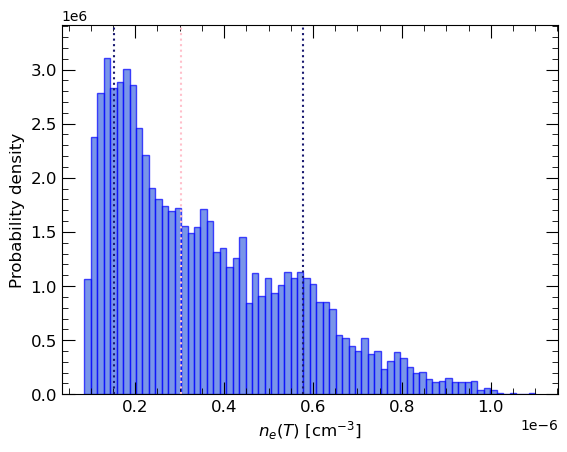

Median = 3.0357749287842667e-07 ; Lower limit =  1.5255335980616565e-07 ; Upper limit =  5.767593035883948e-07
Unshocked values (min e max) [cm-3]: 3.8138339951541413e-08 1.441898258970987e-07


In [108]:
neB_sync = Parallel(n_jobs=ncores, verbose=5)(delayed(ne_from_syn)(pB_rand[i], alphaB_rand[i], c1, c2, nu1, nu2, dkpc, FB_rand[i], VolB) for i in range(niter))
median = np.percentile(neB_sync,50)
low_lim = np.percentile(neB_sync,perc_low)
high_lim = np.percentile(neB_sync,perc_up)
neBs_med = median
neBslow = low_lim
neBsup = high_lim
histplot = plt.hist(neB_sync,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$n_e(T)$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)
print('Unshocked values (min e max) [cm-3]:', low_lim/4, high_lim/4)

In [109]:
def NNtot(p, c1, c12, nu1, nu2, L, B):
    top = (2-p)*(c1**(1/2))*c12*L*(nu2**((1-p)/2)-nu1**((1-p)/2))
    bottom = (1-p)*B*(nu2**((2-p)/2)-nu1**((2-p)/2))
    #print(L, B, nu1, nu2, c1, c12, p)
    return top/bottom

In [110]:
NNA = NNtot(pA, c1, c12, nu1, nu2, LintA, BA)
nnA = NNA/(VolA*f)
print('Electron density in region A considering synchrotron emission at equipartition [1/cm3]', nnA)

Electron density in region A considering synchrotron emission at equipartition [1/cm3] 3.3438356328652336e-07


### CM-based $L_0$ estimate

Time to verify if the model by Kaiser2024 is applycable (hope it is)

$$L_0 = \left[\dfrac{Q_0^2}{\rho_0^2c^6(\gamma_{jet}-1)}\right]^{(1/4)} $$

In [111]:
def L0(Q0, ne):
    rho = ne*1.370*mh
    rho0 = rho/4
    Len = (Q0**2)/((rho0**2)*(c**6)*(gammalor-1))
    Len = Len**(1/4)
    return Len

#### Region C

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


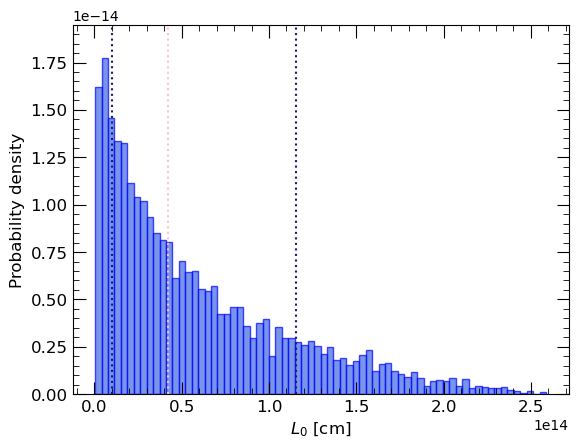

Median = 42123093544232.92 ; Lower limit =  3.2396857312762603e-06 ; Upper limit =  3.744745785534185e-05


In [112]:
L0C = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QC[i], neC[i]) for i in range(niter))
median = np.percentile(L0C,50)
low_lim = np.percentile(L0C,perc_low)
high_lim = np.percentile(L0C,perc_up)
L0C_med = median
L0Clow = low_lim
L0Csup = high_lim
histplot = plt.hist(L0C,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


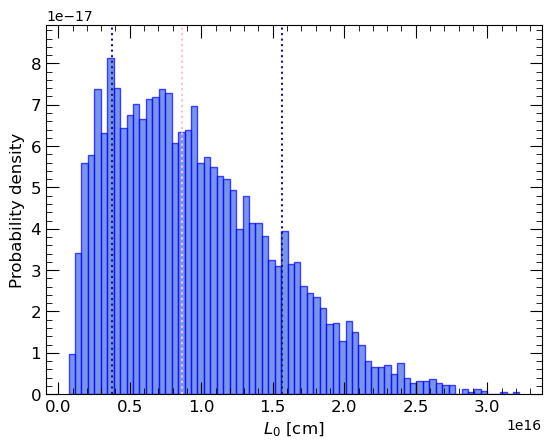

Median = 8662266487932274.0 ; Lower limit =  0.0012160098268609845 ; Upper limit =  0.005065521541785949


In [113]:
L0C_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QC_newvel[i], neC_newvel[i]) for i in range(niter))
median = np.percentile(L0C_newvel,50)
low_lim = np.percentile(L0C_newvel,perc_low)
high_lim = np.percentile(L0C_newvel,perc_up)
L0C_med_new = median
L0Clow_new = low_lim
L0Csup_new = high_lim
histplot = plt.hist(L0C_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


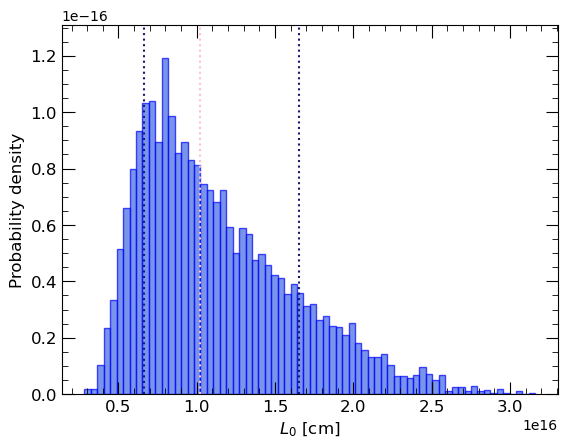

Median = 1.0227388519231084e+16 ; Lower limit =  0.002148027865889804 ; Upper limit =  0.005357846594647131


In [114]:
L0C_new = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QC_new[i], neC_new1[i]) for i in range(niter))
median = np.percentile(L0C_new,50)
low_lim = np.percentile(L0C_new,perc_low)
high_lim = np.percentile(L0C_new,perc_up)
L0C_med_new = median
L0Clow_new = low_lim
L0Csup_new = high_lim
histplot = plt.hist(L0C_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


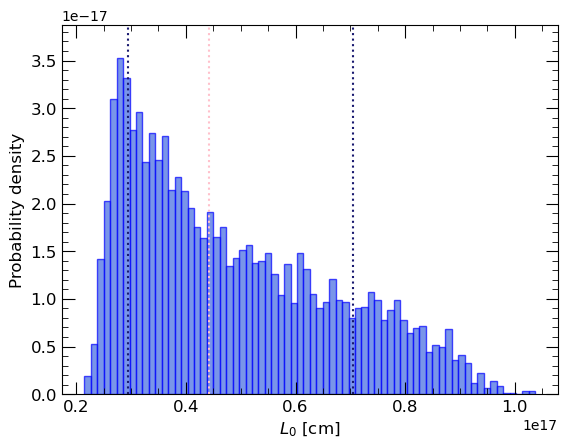

Median = 4.415897334016434e+16 ; Lower limit =  0.009566921355439333 ; Upper limit =  0.022851666883462275


In [115]:
L0C_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QC_new3[i], neC_new3[i]) for i in range(niter))
median = np.percentile(L0C_new3,50)
low_lim = np.percentile(L0C_new3,perc_low)
high_lim = np.percentile(L0C_new3,perc_up)
L0C_med_new3 = median
L0Clow_new3 = low_lim
L0Csup_new3 = high_lim
histplot = plt.hist(L0C_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

#### Region D

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


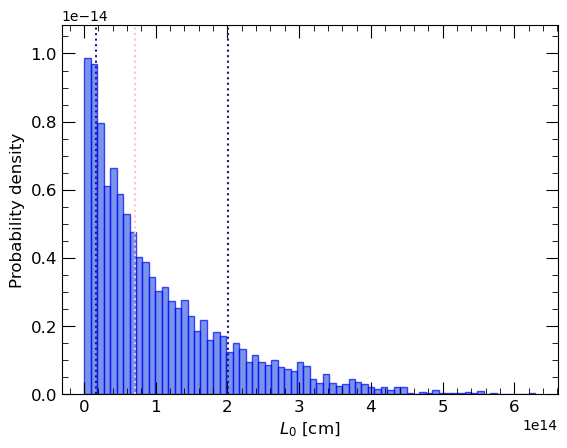

Median = 71435875138869.83 ; Lower limit =  5.476478499343069e-06 ; Upper limit =  6.511302744537816e-05


In [116]:
L0D = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QD[i], neD[i]) for i in range(niter))
median = np.percentile(L0D,50)
low_lim = np.percentile(L0D,perc_low)
high_lim = np.percentile(L0D,perc_up)
L0D_med = median
L0Dlow = low_lim
L0Dsup = high_lim
histplot = plt.hist(L0D,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


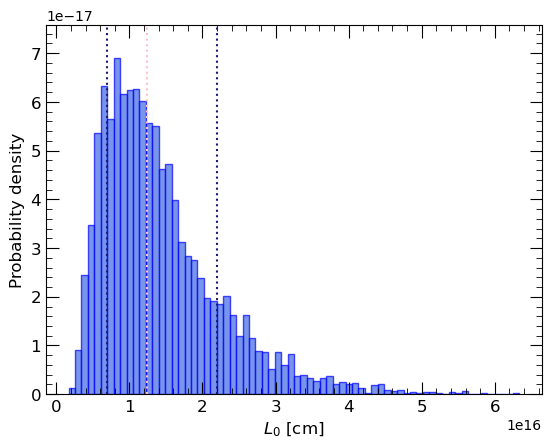

Median = 1.2433634084841704e+16 ; Lower limit =  0.002237119085754222 ; Upper limit =  0.007115902945946607


In [117]:
L0D_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QD_newvel[i], neD_newvel[i]) for i in range(niter))
median = np.percentile(L0D_newvel,50)
low_lim = np.percentile(L0D_newvel,perc_low)
high_lim = np.percentile(L0D_newvel,perc_up)
L0D_med_new3 = median
L0Dlow_new3 = low_lim
L0Dsup_new3 = high_lim
histplot = plt.hist(L0D_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


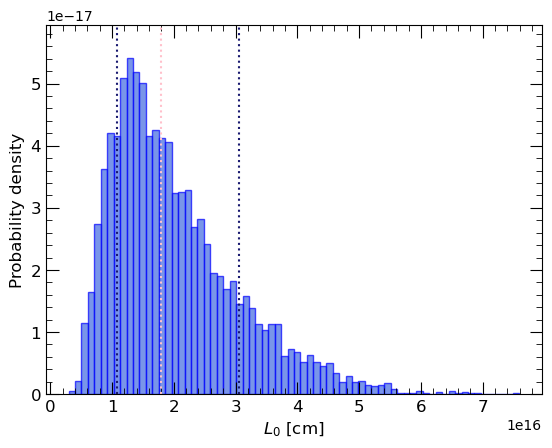

Median = 1.7854368758814836e+16 ; Lower limit =  0.003479024281469932 ; Upper limit =  0.009876431966362405


In [118]:
L0D_new = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QD_new[i], neD_new1[i]) for i in range(niter))
median = np.percentile(L0D_new,50)
low_lim = np.percentile(L0D_new,perc_low)
high_lim = np.percentile(L0D_new,perc_up)
L0D_med_new = median
L0Dlow_new = low_lim
L0Dsup_new = high_lim
histplot = plt.hist(L0D_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


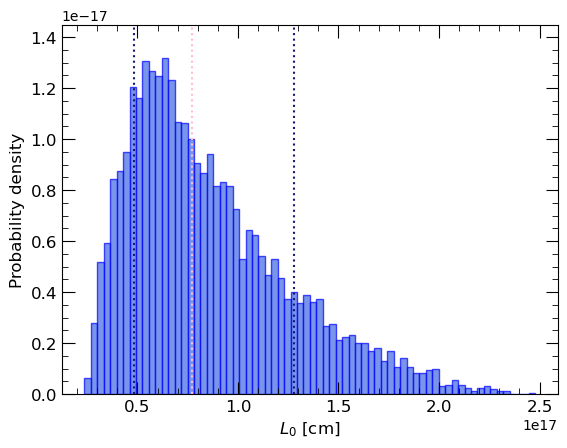

Median = 7.701399841301344e+16 ; Lower limit =  0.015699409491506194 ; Upper limit =  0.04136801658696634


In [119]:
L0D_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QD_new3[i], neD_new3[i]) for i in range(niter))
median = np.percentile(L0D_new3,50)
low_lim = np.percentile(L0D_new3,perc_low)
high_lim = np.percentile(L0D_new3,perc_up)
L0D_med_new3 = median
L0Dlow_new3 = low_lim
L0Dsup_new3 = high_lim
histplot = plt.hist(L0D_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

#### Region E

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


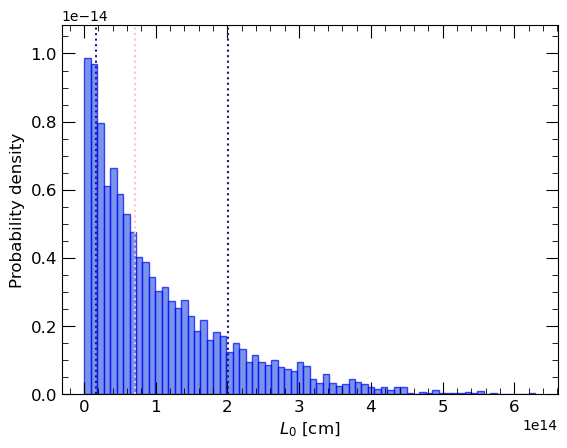

Median = 71435875138869.83 ; Lower limit =  5.476478499343069e-06 ; Upper limit =  6.511302744537816e-05


In [120]:
L0E = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QE[i], neE[i]) for i in range(niter))
median = np.percentile(L0E,50)
low_lim = np.percentile(L0E,perc_low)
high_lim = np.percentile(L0E,perc_up)
L0E_med = median
L0Elow = low_lim
L0Esup = high_lim
histplot = plt.hist(L0E,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


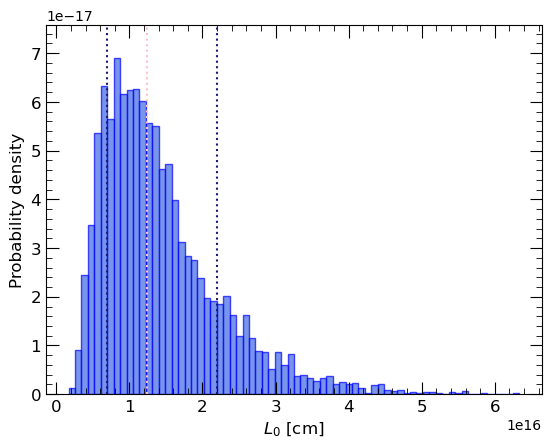

Median = 1.2433634084841704e+16 ; Lower limit =  0.002237119085754222 ; Upper limit =  0.007115902945946607


In [121]:
L0E_newvel = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QE_newvel[i], neE_newvel[i]) for i in range(niter))
median = np.percentile(L0E_newvel,50)
low_lim = np.percentile(L0E_newvel,perc_low)
high_lim = np.percentile(L0E_newvel,perc_up)
L0E_med = median
L0Elow = low_lim
L0Esup = high_lim
histplot = plt.hist(L0E_newvel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


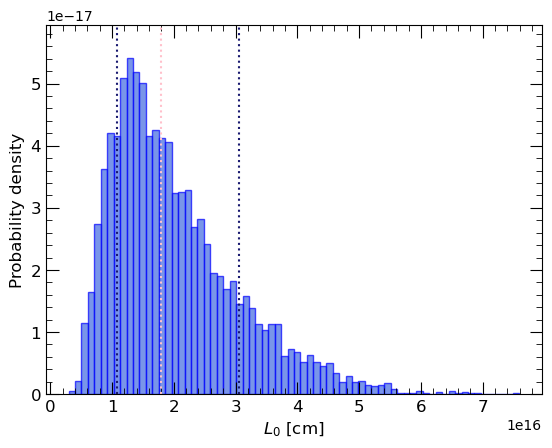

Median = 1.7854368758814838e+16 ; Lower limit =  0.0034790242814699327 ; Upper limit =  0.009876431966362405


In [122]:
L0E_new = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QE_new[i], neE_new1[i]) for i in range(niter))
median = np.percentile(L0E_new,50)
low_lim = np.percentile(L0E_new,perc_low)
high_lim = np.percentile(L0E_new,perc_up)
L0E_med_new = median
L0Elow_new = low_lim
L0Esup_new = high_lim
histplot = plt.hist(L0E_new,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


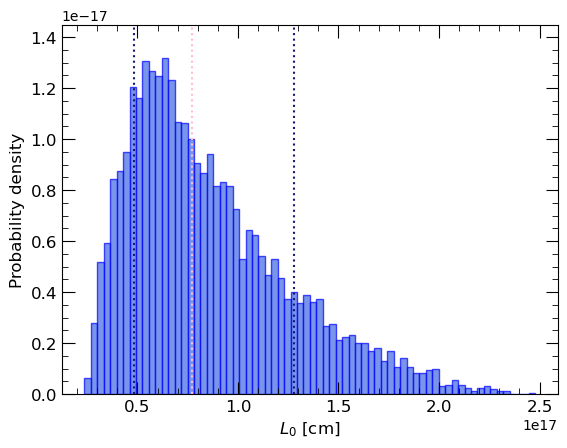

Median = 7.701399841301342e+16 ; Lower limit =  0.015699409491506194 ; Upper limit =  0.04136801658696634


In [123]:
L0E_new3 = Parallel(n_jobs=ncores, verbose=5)(delayed(L0)(QE_new3[i], neE_new3[i]) for i in range(niter))
median = np.percentile(L0E_new3,50)
low_lim = np.percentile(L0E_new3,perc_low)
high_lim = np.percentile(L0E_new3,perc_up)
L0E_med_new3 = median
L0Elow_new3 = low_lim
L0Esup_new3 = high_lim
histplot = plt.hist(L0E_new3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$L_0$ [cm]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim/pc,'; Upper limit = ',high_lim/pc)

#### Data from Martí (VLA) er al 2015 (northern hotspot)

In [124]:
def error_mean(sigmas):
    summ = np.sum(1/sigmas**2)
    return np.sqrt(1/summ)

In [125]:
fluxVLA = np.array([0.37, 0.26, 0.29, 0.26, 0.18])
efluxVLA = np.array([0.03, 0.02, 0.04, 0.04, 0.02])
flumeanVLA = np.mean(fluxVLA)
flustdVLA = np.std(fluxVLA)
eflumeanVLA = error_mean(efluxVLA)
fluMecorr = flumeanVLA*((1.284/4.99)**alphaA)
efluMecorr = np.sqrt(((1.284/4.99)**alphaA)**2*flustdVLA**2)

In [126]:
fluMecorr

0.7696542877223945

In [127]:
efluMecorr

0.17295384559269186

In [128]:
fluMecorr-efluMecorr

0.5967004421297026

In [129]:
FA+eFA

0.33633648265434285

#### Measuring the movement and velocity of the northern bright spot considering VLA images 

In [130]:
#ra97, dec97 = '18:01:13.0141508660', '-25:43:33.9875121247'
#ra97max, ra97min = '18:01:13.058203866', '18:01:12.9700979'
#dec97max, dec97min = '-25:43:34.6483081', ''
#ra24, dec24 = '18:01:13.0447925893', '-25:43:30.3790931214'
#ra97_high = '18:01:13.0447867902'
#coord97 = SkyCoord(ra97, dec97, unit=('hourangle', 'deg'))
#coord24 = SkyCoord(ra24, dec24, unit=('hourangle', 'deg'))
#sep = coord24.separation(coord97).arcsec

In [131]:
#sep

In [132]:
#ra97_rand = np.random.uniform(ra97-ealphaA, ra97+ealphaA, niter)

### Measuring the jet density (momentum per unit mass conserved)

$$\rho_{jet}v_{jet}^2 \approx \rho_{BS}v_{BS}^2$$

where BS = Bow shock, or more generally, the shocked ISM. Resolving for $\rho_{jet}$:

$$\rho_{jet} \approx \rho_{BS}\left(\dfrac{v_{BS}}{v_{jet}}\right)^2 $$

In [133]:
def rho_jet(ne, v, gamma):
    rho = ne#*1.370*mh
    vj = c*np.sqrt(1-(1/(gamma**2)))
    rhoj = rho*((v/vj)**2)
    return rhoj/rho

def rho_jet2(ne, v, vj):
    rho = ne#*1.370*mh
    rhoj = rho*((v/vj)**2)
    return rhoj

In [134]:
gammaj = np.random.uniform(1,5,niter)
vjet = np.random.uniform(0.01*c,c,niter)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


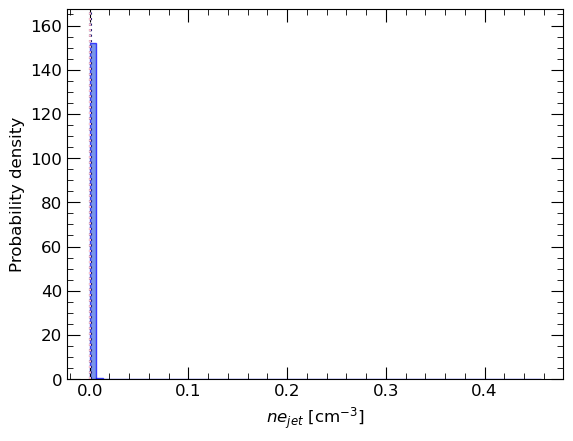

Median = 0.0005038665939201439 ; Lower limit =  0.0002952333663613607 ; Upper limit =  0.0008165757373920388


In [135]:
rhojet = Parallel(n_jobs=ncores, verbose=5)(delayed(rho_jet)(neC[i]/4, vel[i], gammaj[i]) for i in range(niter))

median = np.percentile(rhojet,50)
low_lim = np.percentile(rhojet,perc_low)
high_lim = np.percentile(rhojet,perc_up)
histplot = plt.hist(rhojet,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$ne_{jet}$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s


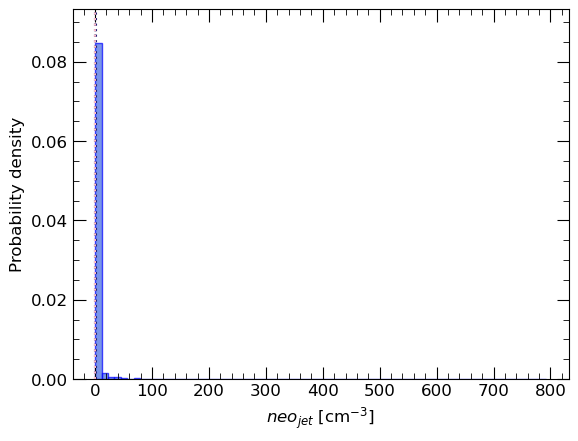

Median = 0.11217273904760441 ; Lower limit =  0.035954326957845305 ; Upper limit =  1.15617201750289


In [136]:
rhojet2 = Parallel(n_jobs=ncores, verbose=5)(delayed(rho_jet2)(neC[i], vel[i], vjet[i]) for i in range(niter))

median = np.percentile(rhojet2,50)
low_lim = np.percentile(rhojet2,perc_low)
high_lim = np.percentile(rhojet2,perc_up)
histplot = plt.hist(rhojet2,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$neo_{jet}$ [cm$^{-3}$]', fontsize=12)
#plt.xlim(0,400)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()
print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

In [137]:
neC[0]

51.37493636870529

In [138]:
np.median(vel)/c

0.020033744254827783

In [139]:
veljet

NameError: name 'veljet' is not defined